# Phase 8b: streaming health monitor (M0, W240)
Online discharge-window builder, `HealthMonitor` (written to `src\health_monitor.py`), serve-parity against stored data, replay, messy-stream tests and latency.
No training. Frozen files are read-only. Section order: S0, S7 (expectations registered), S1, S4, S2, S3, S5, S6, S8, S9, S7 (evaluated), S10. S4 precedes S2 because S2 exercises the monitor's post-processing.

In [1]:
SMOKE = False   # True: 3 cells, 300 sampled cycles, 50 timing repeats, outputs in outputs\phase8b\smoke (never quote smoke results)

import os, sys, json, hashlib, time, platform, subprocess, re, ast, importlib
from pathlib import Path
T_START = time.time()
ROOT = Path(r"C:\workstation\3RD YEAR\Battery-Health-Estimation")
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))


def _ensure(mod):
    try:
        importlib.import_module(mod)
    except ImportError:
        subprocess.check_call(["uv", "pip", "install", "--python", sys.executable, mod])


for _m in ("numpy", "pandas", "h5py", "onnxruntime", "pyarrow", "scipy", "matplotlib"):
    _ensure(_m)

import numpy as np
import pandas as pd
import h5py
import onnxruntime as ort
import scipy
import matplotlib.pyplot as plt

pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 60)
pd.set_option("display.max_rows", 400)

SEED = 42
OUT = ROOT / "outputs" / "phase8b"
if SMOKE:
    OUT = OUT / "smoke"
OUT.mkdir(parents=True, exist_ok=True)
(OUT / "replay").mkdir(exist_ok=True)
LOG = OUT / "phase8b_log.jsonl"
N_PER_BATCH = 300 if SMOKE else 1000
REPEATS = 50 if SMOKE else 200
CAP = 120 if SMOKE else None          # replay cycle cap (smoke only)

REPORT, CHECKS = [], []


def say(*a):
    s = " ".join(str(x) for x in a)
    print(s)
    REPORT.append(s)


def emit(title, obj):
    s = obj.to_string(index=False) if isinstance(obj, pd.DataFrame) else str(obj)
    say("\n=== %s ===\n%s" % (title, s))


def check(name, status, detail):
    assert status in ("PASS", "WARN", "FAIL"), status
    CHECKS.append({"check": name, "status": status, "detail": detail})
    say("[%s] %s: %s" % (status, name, detail))


def sha256_file(p):
    h = hashlib.sha256()
    with open(p, "rb") as f:
        for chunk in iter(lambda: f.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()


def log(event, details):
    prev = ""
    if LOG.exists() and LOG.stat().st_size:
        lines = [l for l in LOG.read_bytes().split(b"\n") if l.strip()]
        prev = hashlib.sha256(lines[-1]).hexdigest()
    line = json.dumps({"event": event, "t_utc": pd.Timestamp.now("UTC").isoformat(), "details": details,
                       "prev_line_sha256": prev}, default=str)
    with open(LOG, "ab") as f:
        f.write(line.encode("utf-8") + b"\n")


def describe_json(obj, name="", depth=0, maxd=4):
    pad = "  " * depth
    if isinstance(obj, dict):
        say("%s%s: dict(%d keys)" % (pad, name, len(obj)))
        if depth < maxd:
            for k, v in list(obj.items())[:25]:
                describe_json(v, str(k), depth + 1, maxd)
    elif isinstance(obj, list):
        say("%s%s: list(len=%d)" % (pad, name, len(obj)))
        if obj and depth < maxd:
            describe_json(obj[0], "[0]", depth + 1, maxd)
    else:
        say("%s%s: %s = %s" % (pad, name, type(obj).__name__, str(obj)[:80]))


# ---- environment
say("Python", platform.python_version(), "| numpy", np.__version__, "| h5py", h5py.__version__,
    "| onnxruntime", ort.__version__, "| pandas", pd.__version__, "| CPU count", os.cpu_count())
_probe = subprocess.run([sys.executable, "-c", "import torch;print(torch.__version__, 'cuda', torch.cuda.is_available())"],
                        capture_output=True, text=True)
say("torch probe (separate process, never imported here):",
    _probe.stdout.strip() if _probe.returncode == 0 else "torch not installed")

# ---- frozen-file guard
EXPECTED = {
    "M0_W240.onnx": (ROOT / "outputs/phase8a/models/M0_W240.onnx", "4fe196d3f7787a4f2dcd5f20939447518afb032eb8dc724c018f891630945771"),
    "M0_W300.onnx": (ROOT / "outputs/phase8a/models/M0_W300.onnx", "4e8cd5235869301eb2694e4b56c346cdb816d06277db7a2914ed0af6580fd1d9"),
    "M0idx_W240.onnx": (ROOT / "outputs/phase8a/models/M0idx_W240.onnx", "50ea2ebbf287ab24a2385bdee8fbe0db4c725442cf4a3076a4daac8063ac2459"),
    "M0idx_W300.onnx": (ROOT / "outputs/phase8a/models/M0idx_W300.onnx", "4c94897e3f765671ad25a412c1f1b78810f660b6bf9262c43cd4d2e6ed2dcd79"),
    "onnx_scorer.py": (ROOT / "src/onnx_scorer.py", "7f56bd5b5df08f7a37bc6104a140da2411b5290d25434a03aa8971599ec139c7"),
    "monitor_config.json": (ROOT / "outputs/phase7b/monitor_config.json", "638b6c3a6ad31c699fb77a22eb9fae72b571d6dc21ee65a73b41e849d7acb4b2"),
    "monitor_config_addendum.json": (ROOT / "outputs/phase7b2/monitor_config_addendum.json", "d842e5f4c3186889ce8292e0654e1a0ca29d4434bcdeaf1bd3c7131479479632"),
    "batch3_predictions.parquet": (ROOT / "outputs/phase7a/batch3_predictions.parquet", "679ec76862de63f2615a710c7fc1f3ca2ec6c01149735bdd909b95ad5a9c7acd"),
}


def hash_guard(tag):
    rows = []
    for name, (path, exp) in EXPECTED.items():
        h = sha256_file(path)
        rows.append({"file": name, "sha256": h, "matches_expected": h == exp})
    emit("hash guard (%s)" % tag, pd.DataFrame(rows))
    bad = [r["file"] for r in rows if not r["matches_expected"]]
    check("hash guard " + tag, "PASS" if not bad else "FAIL",
          "%d/%d frozen files match; mismatches: %s" % (len(rows) - len(bad), len(rows), bad))
    return not bad


assert hash_guard("start"), "a frozen file differs from its expected hash; stop"
log("start", {"smoke": SMOKE, "python": platform.python_version(), "numpy": np.__version__, "h5py": h5py.__version__,
              "onnxruntime": ort.__version__, "cpu_count": os.cpu_count(), "out": str(OUT)})

Python 3.13.13 | numpy 2.5.4 | h5py 3.16.0 | onnxruntime 1.31.1 | pandas 3.1.0 | CPU count 12
torch probe (separate process, never imported here): 2.14.1+cu130 cuda True

=== hash guard (start) ===
                        file                                                           sha256  matches_expected
                M0_W240.onnx 4fe196d3f7787a4f2dcd5f20939447518afb032eb8dc724c018f891630945771              True
                M0_W300.onnx 4e8cd5235869301eb2694e4b56c346cdb816d06277db7a2914ed0af6580fd1d9              True
             M0idx_W240.onnx 50ea2ebbf287ab24a2385bdee8fbe0db4c725442cf4a3076a4daac8063ac2459              True
             M0idx_W300.onnx 4c94897e3f765671ad25a412c1f1b78810f660b6bf9262c43cd4d2e6ed2dcd79              True
              onnx_scorer.py 7f56bd5b5df08f7a37bc6104a140da2411b5290d25434a03aa8971599ec139c7              True
         monitor_config.json 638b6c3a6ad31c699fb77a22eb9fae72b571d6dc21ee65a73b41e849d7acb4b2              True
monitor_config_add

## S0 structure printouts

In [2]:
MATR = ROOT / "data" / "raw" / "MATR"
say("data\\raw\\MATR listing:")
for p in sorted(MATR.iterdir()):
    say("  %-60s %10.1f MB" % (p.name, p.stat().st_size / 1e6))
RAW_FILES = {}
for p in sorted(MATR.iterdir()):
    for pref, b in (("2017-05-12", 1), ("2017-06-30", 2), ("2018-04-12", 3)):
        if p.name.startswith(pref):
            RAW_FILES[b] = p
assert sorted(RAW_FILES) == [1, 2, 3], "could not identify the three MATR files by date prefix: %s" % RAW_FILES

with h5py.File(RAW_FILES[1], "r") as f:
    bt = f["batch"]
    say("batch 1 top-level keys:", list(f.keys()), "| batch keys:", list(bt.keys()))
    for k in bt.keys():
        say("  batch/%s: shape=%s dtype=%s" % (k, bt[k].shape, bt[k].dtype))
    ref = bt["cycles"][0, 0] if bt["cycles"].ndim == 2 and bt["cycles"].shape[1] == 1 else bt["cycles"][0]
    g = f[ref]
    say("cell 0 cycles-group fields:", {k: g[k].shape for k in g.keys()})
    p = 10
    d = {}
    for k in ("V", "Qd", "I", "t"):
        a = f[g[k][p, 0]][()]
        d[k] = (a.shape, str(a.dtype))
    say("cycle position 10 sample arrays (shape, dtype):", d)
    sref = bt["summary"][0, 0] if bt["summary"].ndim == 2 and bt["summary"].shape[1] == 1 else bt["summary"][0]
    s = f[sref]
    say("cell 0 summary fields:", {k: s[k].shape for k in s.keys()})
    vd = bt["Vdlin"]
    vref = vd[0, 0] if vd.ndim == 2 and vd.shape[1] == 1 else vd[0]
    VDLIN = np.asarray(f[vref][()]).ravel().astype(np.float64)
assert VDLIN.size == 1000 and abs(VDLIN[0] - 3.5) < 1e-9 and abs(VDLIN[-1] - 2.0) < 1e-9, "unexpected Vdlin"
say("Vdlin: n=%d first=%.6f last=%.6f spacing=%.7f Vdlin[733]=%.5f" % (VDLIN.size, VDLIN[0], VDLIN[-1], VDLIN[0] - VDLIN[1], VDLIN[733]))

PROC = ROOT / "data" / "processed"
for p in sorted(PROC.iterdir()):
    say("  data\\processed\\%-34s %10.1f MB" % (p.name, p.stat().st_size / 1e6))
CFG_PATHS = [ROOT / "outputs/phase7b/monitor_config.json", ROOT / "outputs/phase7b2/monitor_config_addendum.json"]
for cp in CFG_PATHS:
    say("\nstructure of", cp.name)
    describe_json(json.loads(cp.read_text(encoding="utf-8")), cp.name)

data\raw\MATR listing:
  2017-05-12_batchdata_updated_struct_errorcorrect.mat             3025.3 MB
  2017-06-30_batchdata_updated_struct_errorcorrect.mat             2007.3 MB
  2018-04-12_batchdata_updated_struct_errorcorrect.mat             3236.7 MB
batch 1 top-level keys: ['#refs#', '#subsystem#', 'batch', 'batch_date'] | batch keys: ['Vdlin', 'barcode', 'channel_id', 'cycle_life', 'cycles', 'policy', 'policy_readable', 'summary']
  batch/Vdlin: shape=(46, 1) dtype=object
  batch/barcode: shape=(46, 1) dtype=object
  batch/channel_id: shape=(46, 1) dtype=object
  batch/cycle_life: shape=(46, 1) dtype=object
  batch/cycles: shape=(46, 1) dtype=object
  batch/policy: shape=(46, 1) dtype=object
  batch/policy_readable: shape=(46, 1) dtype=object
  batch/summary: shape=(46, 1) dtype=object
cell 0 cycles-group fields: {'I': (1189, 1), 'Qc': (1189, 1), 'Qd': (1189, 1), 'Qdlin': (1189, 1), 'T': (1189, 1), 'Tdlin': (1189, 1), 'V': (1189, 1), 'discharge_dQdV': (1189, 1), 't': (1189, 1)}
cy

## S7 expectations (registered here, before any parity, replay or timing number exists; evaluated at the end)

In [3]:
EXPECT = [
    {"id": "H16", "statement": "online window vs stored Qdlin: p99 of per-cycle max |diff| <= 6e-3 Ah", "limit": {"p99_ah": 6e-3}},
    {"id": "H17", "statement": "online raw estimate vs offline: median |diff| <= 0.02 pp and p99 <= 0.10 pp", "limit": {"median_pp": 0.02, "p99_pp": 0.10}},
    {"id": "H18", "statement": "monitor references and Q0 equal the stored ones for the 12 regular replay cells (b1c18, b1c41 may differ)", "limit": {"q0_tol_ah": 1e-6}},
    {"id": "H19", "statement": "replay fire cycles equal offline for >= 90% of cell x alert pairs and within 2 cycles otherwise", "limit": {"share_equal": 0.90, "max_gap_cycles": 2}},
    {"id": "H20", "statement": "per-cell update p99 <= 10 ms and fleet update median <= 50 ms in every pass", "limit": {"cell_p99_ms": 10.0, "fleet_median_ms": 50.0}},
]
emit("expectations registered (H16-H20)", pd.DataFrame([{"id": e["id"], "expectation": e["statement"]} for e in EXPECT]))
log("expectations_registered", {"expectations": EXPECT})


=== expectations registered (H16-H20) ===
 id                                                                                               expectation
H16                                     online window vs stored Qdlin: p99 of per-cycle max |diff| <= 6e-3 Ah
H17                               online raw estimate vs offline: median |diff| <= 0.02 pp and p99 <= 0.10 pp
H18 monitor references and Q0 equal the stored ones for the 12 regular replay cells (b1c18, b1c41 may differ)
H19           replay fire cycles equal offline for >= 90% of cell x alert pairs and within 2 cycles otherwise
H20                               per-cell update p99 <= 10 ms and fleet update median <= 50 ms in every pass


## S1 raw reader and recipe calibration

In [4]:
STITCHED = {"b1c0", "b1c1", "b1c2", "b1c3", "b1c4"}


def parse_cell(cid):
    m = re.fullmatch(r"b(\d)c(\d+)", cid)
    assert m, cid
    return int(m.group(1)), int(m.group(2))


class RawMatr:
    # read-only reader: V, Qd, I, t of one (cell, cycle) plus the summary QDischarge
    def __init__(self, files):
        self.h = {b: h5py.File(p, "r") for b, p in files.items()}
        self._cell = {}

    @staticmethod
    def _idx(ds, p):
        if ds.ndim == 2:
            return (p, 0) if ds.shape[1] == 1 else (0, p)
        return p

    def _group(self, b, i):
        key = (b, i)
        if key not in self._cell:
            f = self.h[b]
            bt = f["batch"]
            g = f[bt["cycles"][self._idx(bt["cycles"], i)]]
            s = f[bt["summary"][self._idx(bt["summary"], i)]]
            cyc = np.asarray(s["cycle"][()]).ravel()
            qd = np.asarray(s["QDischarge"][()]).ravel()
            sm = {int(c): float(q) for c, q in zip(cyc, qd) if np.isfinite(c)}
            self._cell[key] = (g, sm)
        return self._cell[key]

    def n_cycles(self, b, i):
        g, _ = self._group(b, i)
        return int(max(g["V"].shape))

    def _arr(self, f, ds, p):
        return np.asarray(f[ds[self._idx(ds, p)]][()], dtype=np.float64).ravel()

    def read(self, b, i, cycle_number):
        g, sm = self._group(b, i)
        p = cycle_number - 1                       # array position p is cycle_number p+1
        if p < 0 or p >= self.n_cycles(b, i):
            return None
        f = self.h[b]
        out = {k: self._arr(f, g[k], p) for k in ("V", "Qd", "I", "t")}
        if out["V"].size < 10 or not (out["V"].size == out["Qd"].size == out["I"].size == out["t"].size):
            return None                            # empty placeholder or inconsistent record
        out["qd_sum"] = sm.get(int(cycle_number), np.nan)
        return out


RAW = RawMatr(RAW_FILES)


def seg(rec, pad=3):
    # discharge segment: first sample with I <= -1.0 A, to the end of that contiguous run
    I = rec["I"]
    idx = np.flatnonzero(I <= -1.0)
    if idx.size == 0:
        return None
    s = int(idx[0])
    rest = np.flatnonzero(I[s:] > -1.0)
    e = s + (int(rest[0]) if rest.size else I.size - s)
    return slice(max(s - pad, 0), e)


RAWC = {}


def get_raw(cid, c, cache=False):
    # returns (V, Qd, I, t, qd_summary) trimmed to the discharge run, or None for an empty/absent cycle
    key = (cid, c)
    if key in RAWC:
        return RAWC[key]
    b, i = parse_cell(cid)
    rec = RAW.read(b, i, c)
    if rec is None:
        out = None
    else:
        sl = seg(rec) or slice(0, 10)
        out = (rec["V"][sl].copy(), rec["Qd"][sl].copy(), rec["I"][sl].astype(np.float32),
               rec["t"][sl].astype(np.float32), rec["qd_sum"])
    if cache:
        RAWC[key] = out
    return out


# ---- labels table (needed for calibration rows)
lab = pd.read_parquet(PROC / "labels_table_v2.parquet").sort_values("row_id").reset_index(drop=True)
say("labels_table_v2 columns:", list(lab.columns), "| rows:", len(lab))
for c in ("row_id", "cell_id", "batch", "cycle_number", "is_ref", "q0", "ref_last", "score_start", "soh_nom", "scored2"):
    assert c in lab.columns, "labels table lacks column " + c
QD = np.load(PROC / "qdlin_f32.npy", mmap_mode="r")
assert QD.shape == (104971, 1000) and QD.dtype == np.float32, (QD.shape, QD.dtype)
assert len(lab) == QD.shape[0] and (lab.row_id.values == np.arange(len(lab))).all(), "row_id is not the row position"


def row_of(cid, cyc):
    r = lab.loc[(lab.cell_id == cid) & (lab.cycle_number == cyc), "row_id"]
    return int(r.iloc[0]) if len(r) else None


# ---- candidate recipes
CAL_CELLS = ["b1c5", "b2c5", "b1c30"]
CANDS = {}
for _dup in ("none", "first", "last"):
    for _off in ("interp0", "first_sample"):
        CANDS["runmin|%s|%s" % (_dup, _off)] = {"runmin": True, "dup": _dup, "offset": _off}
CANDS["nomin|none|interp0 (info only)"] = {"runmin": False, "dup": "none", "offset": "interp0"}


def cal_window(V, Qd, I, r, n=734):
    s = int(np.flatnonzero(I <= -1.0)[0])
    v, q = V[s:], Qd[s:]
    rm = np.minimum.accumulate(v)
    k = int(np.argmax(rm <= VDLIN[n - 1]))
    assert rm[k] <= VDLIN[n - 1], "tau not reached"
    vv = (rm if r["runmin"] else v)[:k + 1]
    q = q[:k + 1]
    m = np.ones(vv.size, bool)
    if r["dup"] == "first":
        m[1:] = vv[1:] < vv[:-1]
    elif r["dup"] == "last":
        m[:-1] = vv[1:] < vv[:-1]
    w = np.interp(VDLIN[:n], vv[m][::-1], q[m][::-1])
    return w - (w[0] if r["offset"] == "interp0" else q[0])


errs = []
for cid in CAL_CELLS:
    b, i = parse_cell(cid)
    for cyc in range(20, 50):
        row = row_of(cid, cyc)
        rec = RAW.read(b, i, cyc)
        if row is None or rec is None:
            continue
        stored = np.asarray(QD[row, :734], dtype=np.float64)
        if not np.all(np.isfinite(stored)):
            continue
        for name, r in CANDS.items():
            errs.append({"cell_id": cid, "cycle": cyc, "recipe": name,
                         "err": float(np.max(np.abs(cal_window(rec["V"], rec["Qd"], rec["I"], r) - stored)))})
E = pd.DataFrame(errs)
assert len(E) > 0, "no calibration cycles could be compared"
tab = E.groupby("recipe").err.agg(max_err="max", p99=lambda x: x.quantile(0.99), median="median", n="size")
for cid in CAL_CELLS:
    tab["max_" + cid] = E[E.cell_id == cid].groupby("recipe").err.max()
tab = tab.reset_index().sort_values("max_err")
emit("S1 calibration: max abs error (Ah) of the W240 window vs stored Qdlin, cycles 20..49", tab)
elig = tab[tab.recipe.str.startswith("runmin")].sort_values(["max_err", "median"])
best = elig.iloc[0]
RECIPE = {k: v for k, v in CANDS[best.recipe].items() if k != "runmin"}
say("frozen recipe:", RECIPE, "(max error %.6f Ah)" % best.max_err)
check("S1 recipe calibration", "PASS" if best.max_err <= 6e-3 else "WARN",
      "best recipe %s, max error %.6f Ah, p99 %.6f Ah over %d cycles; earlier work: ~0.0056 Ah" % (best.recipe, best.max_err, best.p99, int(best.n)))
log("recipe_frozen", {"recipe": RECIPE, "table": tab.round(6).to_dict("records")})


# ---- reference-gate calibration on the STORED reference cycles (is_ref) of all non-stitched kept cells.
# The earlier version used p99 |I - median| over a segment that starts at I <= -1 A; the ramp from -1 A to the plateau
# made that statistic 1.3-1.9 A and the tolerance 5.8 A, which rejected nothing. The gate now checks the plateau:
# (1) median current vs nominal, (2) share of samples within a narrow band of that median.
def _up(x, nd=3):
    return float(np.ceil(x * 10 ** nd - 1e-9) / 10 ** nd)


_kept_g = pd.read_csv(ROOT / "outputs/phase3/kept_cells_groups_strata.csv")
_reg_g = pd.read_csv(PROC / "cell_registry_final.csv")
_stc = set(STITCHED)
for _c in _reg_g.columns:
    if "stitch" in _c.lower():
        _s = _reg_g[_c]
        _stc |= set(_reg_g.loc[_s.notna() & ~_s.astype(str).str.strip().str.lower().isin(["", "nan", "none", "false", "0"]), "cell_id"])
        break
_refs = lab[lab.is_ref.fillna(False).astype(bool) & lab.cell_id.isin(set(_kept_g.cell_id) - _stc)]
_gate = []
for _r in _refs.itertuples():
    cid, cyc = _r.cell_id, int(_r.cycle_number)
    b, i = parse_cell(cid)
    rec = RAW.read(b, i, cyc)
    if rec is None or not np.isfinite(rec["qd_sum"]):
        continue
    I_, Q_, V_ = rec["I"], rec["Qd"], rec["V"]
    idx = np.flatnonzero(I_ <= -1.0)
    if idx.size == 0:
        continue
    s0 = int(idx[0])
    rest = np.flatnonzero(I_[s0:] > -1.0)
    e0 = s0 + (int(rest[0]) if rest.size else I_.size - s0)
    vm = np.minimum.accumulate(V_[s0:e0])
    k = int(np.argmax(vm <= VDLIN[733]))
    if vm[k] > VDLIN[733]:
        continue
    pre = I_[s0:s0 + k + 1]
    med = float(np.median(pre))
    _gate.append({"cell_id": cid, "cycle": cyc, "qd_summary": float(rec["qd_sum"]), "i_median": med,
                  "i_plateau_frac": float(np.mean(np.abs(pre - med) <= 0.1)),
                  "end_gap_ah": abs(float(Q_[e0 - 1]) - float(rec["qd_sum"]))})
GT = pd.DataFrame(_gate)
assert len(GT) > 0, "no stored reference cycles for the reference-gate calibration"
I_NOM = round(float(GT.i_median.median()), 1)
GT["i_med_dev"] = (GT.i_median - I_NOM).abs()
emit("S1 reference-gate calibration: %d stored reference cycles, %d cells" % (len(GT), GT.cell_id.nunique()),
     GT[["qd_summary", "i_median", "i_med_dev", "i_plateau_frac", "end_gap_ah"]].describe().T.round(5).reset_index().rename(columns={"index": "statistic"}))
GATE = {"i_nom": I_NOM,
        "i_tol": max(0.05, _up(10 * float(GT.i_med_dev.max()))),
        "i_min_frac": max(0.5, float(np.floor((float(GT.i_plateau_frac.min()) - 0.05) * 100) / 100)),
        "end_tol": max(0.01, _up(2 * float(GT.end_gap_ah.max()) + 5e-4))}
say("reference gates (calibrated):", GATE)
check("S1 reference gates", "PASS" if (GATE["end_tol"] < 0.04 and GATE["i_tol"] <= 0.25) else "WARN",
      "nominal %.1f A, median tolerance %.3f A, plateau fraction >= %.2f (band 0.1 A), end-capacity tolerance %.3f Ah "
      "(S8 test g injects a 0.05 Ah mismatch, S8 test g2 scales the current by x0.8 and x1.10)"
      % (GATE["i_nom"], GATE["i_tol"], GATE["i_min_frac"], GATE["end_tol"]))
log("reference_gates", {"gate": GATE, "n_cycles": len(GT), "n_cells": int(GT.cell_id.nunique())})


labels_table_v2 columns: ['row_id', 'cell_id', 'batch', 'cycle_number', 'segment', 'in_life', 'qdlin_ok', 'causal_ok', 'label_suspect', 'post_junction', 'is_ref', 'q0', 'ref_last', 'score_start', 'soh_nom', 'soh_rel', 'soh_nom_repaired', 'scored', 'scored_incl_suspect', 'train_ok', 'ratio_end', 'max_step', 'qdlin_tail_suspect', 'qdlin_ok2', 'scored2', 'high_defect_cell'] | rows: 104971

=== S1 calibration: max abs error (Ah) of the W240 window vs stored Qdlin, cycles 20..49 ===
                        recipe  max_err      p99   median  n  max_b1c5  max_b2c5  max_b1c30
nomin|none|interp0 (info only) 0.002086 0.001558 0.000935 90   0.00119  0.002086   0.001234
     runmin|first|first_sample 0.002086 0.001558 0.000963 90   0.00124  0.002086   0.001425
          runmin|first|interp0 0.002086 0.001558 0.000935 90   0.00119  0.002086   0.001234
      runmin|last|first_sample 0.002086 0.001558 0.000963 90   0.00124  0.002086   0.001425
           runmin|last|interp0 0.002086 0.001558 0.000935

## S4 src\health_monitor.py (written and imported here; S2 uses it)

In [5]:
MODULE_SRC = r'''# health_monitor.py : streaming SOH monitor for the MATR capacity-free nowcast (phase 8b).
# Dependencies: numpy, json, time, math, pathlib, and onnxruntime through src.onnx_scorer only.
# This module must never import torch or any src.soh_deep_* module.
import json
import math
import time
from pathlib import Path

import numpy as np

from src.onnx_scorer import OnnxScorer

NAN = float("nan")
VGRID = np.linspace(3.5, 2.0, 1000)          # voltage grid Vdlin (3.5 V down to 2.0 V)
WINDOW_LEN = {"W240": 734, "W300": 334}      # window = grid indices 0..n-1, closes at VGRID[n-1]
START_I = -1.0                               # discharge starts at the first sample with I <= -1.0 A
REF_START = 8                                # references use cycles with cycle_number >= 8
N_REF = 5                                    # number of reference cycles
SCORE_GAP = 8                                # scoring starts at ref_last + 8
REF_JOIN_MAX = 8                             # a cell first seen after this cycle cannot build a reference
REF_DEADLINE = 60                            # references must complete by this cycle number
WARN_PP = 85.0                               # warn85: raw <= 85.0
EOL_PP = 80.0                                # eol_watch: lower_bound <= 80.0
THRESH = {"first_abs": 0.01, "mono_tol": 5e-3, "lo": -0.02, "hi": 1.2, "max_step": 0.05}
REF_QD_RANGE = (0.5, 1.3)                    # Ah, summary discharge capacity
REF_END_TOL = __ENDTOL__                     # Ah, raw end capacity vs summary capacity (calibrated on clean cycles)
REF_I_NOM = __INOM__                         # A, nominal discharge current (calibrated on clean cycles)
REF_I_TOL = __ITOL__                         # A, |median discharge current up to tau - nominal|
REF_I_BAND = 0.1                             # A, plateau band around the median current
REF_I_MIN_FRAC = __IMINFRAC__                # minimum share of samples up to tau inside that band
DEFAULT_RECIPE = {"dup": "__DUP__", "offset": "__OFFSET__"}
REC_KEYS = ("raw", "ema", "lo", "hi", "lower_bound")


# ---------------------------------------------------------------- configuration tables
_REQ = {"pred_lo", "pred_hi", "q2_pooled", "ql_pooled"}


def _tokens(path):
    out = set()
    for p in path:
        s = "".join(ch if ch.isalnum() else " " for ch in str(p)).lower()
        out.update(s.split())
    return out


def _walk(obj, path, found):
    if isinstance(obj, dict):
        if _REQ <= set(obj) and all(isinstance(obj[k], list) for k in _REQ):
            found.append((path, {k: list(obj[k]) for k in _REQ}))
            return
        for k, v in obj.items():
            _walk(v, path + [str(k)], found)
    elif isinstance(obj, list):
        if obj and all(isinstance(x, dict) and _REQ <= set(x) for x in obj):
            found.append((path, {k: [x[k] for x in obj] for k in _REQ}))
            return
        for j, v in enumerate(obj):
            _walk(v, path + [str(j)], found)


def _alpha_cands(obj, path, out):
    # every numeric value stored under a key that contains "alpha", with its path
    if isinstance(obj, dict):
        for k, v in obj.items():
            if "alpha" in str(k).lower() and isinstance(v, (int, float)) and not isinstance(v, bool):
                out.append((path + [str(k)], float(v)))
            elif isinstance(v, (dict, list)):
                _alpha_cands(v, path + [str(k)], out)
    elif isinstance(obj, list):
        for j, v in enumerate(obj):
            _alpha_cands(v, path + [str(j)], out)


def _num(x, default):
    return default if x is None else float(x)


def load_tables(config_paths, window, series="raw"):
    # Finds the conformal bin table for (window, series) in one or more JSON config files.
    # Raises ValueError (listing the candidates) if zero or several different tables match.
    if isinstance(config_paths, (str, Path)):
        config_paths = [config_paths]
    found, acands, cfgs = [], [], []
    for cp in config_paths:
        cfg = json.loads(Path(cp).read_text(encoding="utf-8"))
        cfgs.append((Path(cp).name, cfg))
        _walk(cfg, [Path(cp).name], found)
        _alpha_cands(cfg, [Path(cp).name], acands)
    pick = None
    for nm, cfg in cfgs:
        e = cfg.get("ema") if isinstance(cfg, dict) else None
        ch = e.get("chosen") if isinstance(e, dict) else None
        v = ch.get(window) if isinstance(ch, dict) else None
        if isinstance(v, (int, float)) and not isinstance(v, bool):
            pick = ([nm, "ema", "chosen", window], float(v))
            break
    if pick is None:
        for p, v in acands:
            tk = _tokens(p)
            if tk & {"ema", "ewma", "ewm"} and not tk & {"mae", "oof", "dev"}:
                pick = (p, v)
                break
    if pick is None:
        for p, v in acands:
            if abs(v - 0.3) < 1e-12:
                pick = (p, v)
                break
    alpha = 0.3 if pick is None else pick[1]
    alpha_src = "default 0.3 (no EMA alpha found in the config files)" if pick is None else " / ".join(pick[0])
    other = "ema" if series == "raw" else "raw"
    cands = []
    for p, t in found:
        tok = _tokens(p)
        if window.lower() in tok and series in tok and other not in tok:
            cands.append((p, t))
    uniq = []
    for p, t in cands:
        if not any(t == u[1] for u in uniq):
            uniq.append((p, t))
    if len(uniq) != 1:
        listing = [" / ".join(p) for p, _ in (cands if cands else found)]
        raise ValueError("expected exactly one conformal table for %s/%s, found %d distinct; candidates: %s"
                         % (window, series, len(uniq), listing))
    path, t = uniq[0]
    hi = np.array([_num(x, np.inf) for x in t["pred_hi"]], dtype=float)
    lo = np.array([_num(x, -np.inf) for x in t["pred_lo"]], dtype=float)
    order = np.argsort(hi, kind="stable")
    tab = {"lo": lo[order], "hi": hi[order],
           "q2": np.array([float(x) for x in t["q2_pooled"]], dtype=float)[order],
           "ql": np.array([float(x) for x in t["ql_pooled"]], dtype=float)[order],
           "alpha": float(alpha), "alpha_src": alpha_src,
           "alpha_candidates": [(" / ".join(p), v) for p, v in acands], "path": " / ".join(path)}
    if not np.all(np.diff(tab["hi"]) >= 0):
        raise ValueError("pred_hi is not ascending in table " + tab["path"])
    return tab


def bin_index(tab, x, conv="hi_ge"):
    # hi_ge: first bin whose pred_hi >= x ; hi_gt: first bin whose pred_hi > x ; lo: last bin whose pred_lo <= x.
    x = np.asarray(x, dtype=float)
    n = len(tab["hi"])
    if conv == "hi_ge":
        i = np.searchsorted(tab["hi"], x, side="left")
    elif conv == "hi_gt":
        i = np.searchsorted(tab["hi"], x, side="right")
    elif conv == "lo":
        i = np.searchsorted(tab["lo"], x, side="right") - 1
    else:
        raise ValueError("unknown bin convention " + str(conv))
    return np.clip(i, 0, n - 1)


# ---------------------------------------------------------------- window construction
def compute_window(vmin, q, n, recipe=None):
    # vmin: running minimum of V up to tau (non-increasing); q: cumulative discharge capacity (Ah).
    r = recipe or DEFAULT_RECIPE
    vmin = np.asarray(vmin, dtype=float)
    q = np.asarray(q, dtype=float)
    m = np.ones(len(vmin), dtype=bool)
    if r["dup"] == "first":
        m[1:] = vmin[1:] < vmin[:-1]
    elif r["dup"] == "last":
        m[:-1] = vmin[1:] < vmin[:-1]
    xp = vmin[m][::-1]
    fp = q[m][::-1]
    w = np.interp(VGRID[:n], xp, fp)
    off = w[0] if r["offset"] == "interp0" else q[0]
    return w - off


class WindowBuilder:
    # Accepts discharge samples one at a time; emits the window at tau using only samples up to tau.
    def __init__(self, window="W240", recipe=None):
        self.n = WINDOW_LEN[window]
        self.vtau = float(VGRID[self.n - 1])
        self.recipe = dict(recipe or DEFAULT_RECIPE)
        self.reset()

    def reset(self):
        self.started = False
        self.ended = False
        self.done = False
        self.vm = float("inf")
        self._v = []
        self._q = []
        self.window = None
        self.t_start = None
        self.t_tau = None
        self.end_q = None
        self.cur = []
        self.bad = 0
        self.n_pushed = 0
        self.win_s = 0.0

    def push(self, v, q, i=None, t=None):
        # returns True exactly once: when tau is reached and the window has been built
        if self.ended:
            return False
        if not self.started:
            if i is not None and not (i <= START_I):
                return False
            self.started = True
            self.t_start = t
        elif i is not None and i > START_I:
            self.ended = True
            return False
        self.n_pushed += 1
        if i is not None and not self.done:
            self.cur.append(i)
        if not (math.isfinite(v) and math.isfinite(q)):
            if not self.done:
                self.bad += 1
            return False
        self.end_q = q
        if v < self.vm:
            self.vm = v
        if self.done:
            return False
        self._v.append(self.vm)
        self._q.append(q)
        if self.vm <= self.vtau:
            self.done = True
            self.t_tau = t
            t0 = time.perf_counter()
            self.window = compute_window(self._v, self._q, self.n, self.recipe)
            self.win_s = time.perf_counter() - t0
            return True
        return False

    def process(self, V, Qd, I=None, t=None, stop_at_tau=False):
        # batch function: same code path (push) as the per-sample interface
        Vl = np.asarray(V, dtype=float).tolist()
        Ql = np.asarray(Qd, dtype=float).tolist()
        n = len(Vl)
        Il = [None] * n if I is None else np.asarray(I, dtype=float).tolist()
        Tl = [None] * n if t is None else np.asarray(t, dtype=float).tolist()
        push = self.push
        for v, q, i, tt in zip(Vl, Ql, Il, Tl):
            hit = push(v, q, i, tt)
            if self.ended or (hit and stop_at_tau):
                break
        return self.window


def validate_window(w, n=None):
    # serving-side causal check; never repairs. Returns (ok, reason).
    w = np.asarray(w, dtype=float)
    if w.ndim != 1 or (n is not None and w.size != n):
        return False, "bad shape %s" % (w.shape,)
    if not np.all(np.isfinite(w)):
        return False, "non-finite values"
    if abs(w[0]) > THRESH["first_abs"]:
        return False, "first value %.4f Ah not near zero" % w[0]
    d = np.diff(w)
    if d.min() < -THRESH["mono_tol"]:
        return False, "non-monotone (min step %.4f Ah)" % d.min()
    if w.min() < THRESH["lo"] or w.max() > THRESH["hi"]:
        return False, "value range [%.3f, %.3f] Ah" % (w.min(), w.max())
    if np.abs(d).max() > THRESH["max_step"]:
        return False, "step %.4f Ah between neighbouring grid points" % np.abs(d).max()
    return True, ""


# ---------------------------------------------------------------- per-cell state
class CellState:
    _FIELDS = ("cell_id", "ref_cycles", "ref_q", "ref_last", "q0", "score_start", "no_ref", "first_cycle",
               "last_cycle", "n_ingested", "ema", "last", "stale", "warn85_cycle", "eol_cycle")

    def __init__(self, cell_id):
        self.cell_id = cell_id
        self.ref_cycles = []
        self.ref_windows = []
        self.ref_q = []
        self.qref = None
        self.q0 = None
        self.ref_last = None
        self.score_start = None
        self.no_ref = False
        self.first_cycle = None
        self.last_cycle = None
        self.n_ingested = 0
        self.ema = None
        self.last = None
        self.stale = False
        self.warn85_cycle = None
        self.eol_cycle = None

    def to_dict(self):
        d = {k: getattr(self, k) for k in self._FIELDS}
        d["ref_cycles"] = [int(c) for c in self.ref_cycles]
        d["ref_q"] = [float(x) for x in self.ref_q]
        d["ref_windows"] = [[float(x) for x in w] for w in self.ref_windows]
        d["qref"] = None if self.qref is None else [float(x) for x in np.asarray(self.qref, dtype=float)]
        d["last"] = None if self.last is None else {k: float(v) for k, v in self.last.items()}
        return d

    @classmethod
    def from_dict(cls, d):
        st = cls(d["cell_id"])
        for k in cls._FIELDS:
            setattr(st, k, d[k])
        st.ref_windows = [list(w) for w in d["ref_windows"]]
        st.qref = None if d["qref"] is None else np.asarray(d["qref"], dtype=float)
        return st


# ---------------------------------------------------------------- the monitor
class HealthMonitor:
    def __init__(self, model_dir, config_path, window="W240", variant="M0", grid_path=None, recipe=None,
                 bin_convention="hi_ge", intra_op_threads=1):
        if window not in WINDOW_LEN:
            raise ValueError("window must be one of %s" % list(WINDOW_LEN))
        if variant not in ("M0", "M0idx"):
            raise ValueError("variant must be M0 or M0idx")
        self.window, self.variant = window, variant
        self.experimental = variant != "M0"       # M0idx (log1p cycle input) is experimental
        self.n = WINDOW_LEN[window]
        model_dir = Path(model_dir)
        self.scorer = OnnxScorer(str(model_dir / ("%s_%s.onnx" % (variant, window))), intra_op_threads=intra_op_threads)
        gp = Path(grid_path) if grid_path else model_dir.parents[1] / "phase7a" / "models" / ("M0_%s.npz" % window)
        with np.load(gp, allow_pickle=False) as z:
            self.grid = np.asarray(z["grid"]).astype(np.int64)
        if self.grid.size != 32 or self.grid[0] != 0 or np.any(np.diff(self.grid) <= 0) or self.grid[-1] >= self.n:
            raise ValueError("subsample grid must be 32 increasing indices in 0..%d starting at 0" % (self.n - 1))
        self.tab = load_tables(config_path, window, "raw")
        self.alpha = float(self.tab["alpha"])
        self.recipe = dict(recipe or DEFAULT_RECIPE)
        self.bin_convention = bin_convention
        self.cells = {}
        self._open = {}
        self.orphans = []
        self.last_timing = {}

    # ---- state helpers
    def _get(self, cell_id):
        st = self.cells.get(cell_id)
        if st is None:
            st = CellState(cell_id)
            self.cells[cell_id] = st
        return st

    def state_dict(self, cell_id):
        return self.cells[cell_id].to_dict()

    def load_state(self, d):
        st = CellState.from_dict(d)
        self.cells[st.cell_id] = st
        return st

    def set_reference(self, cell_id, qref, q0, ref_last, ref_cycles=None):
        st = self._get(cell_id)
        st.qref = np.asarray(qref, dtype=float)
        st.q0 = float(q0)
        st.ref_last = int(ref_last)
        st.score_start = int(ref_last) + SCORE_GAP
        st.ref_cycles = [] if ref_cycles is None else [int(c) for c in ref_cycles]
        st.first_cycle = 1
        st.no_ref = False
        return st

    # ---- records
    def _blank(self, st, cycle, status, stale=False, carry=False):
        rec = {"cell_id": st.cell_id, "cycle": int(cycle), "status": status,
               "raw": NAN, "ema": NAN, "lo": NAN, "hi": NAN, "lower_bound": NAN,
               "warn85": st.warn85_cycle is not None, "eol_watch": st.eol_cycle is not None,
               "stale": bool(stale), "latency_ms": 0.0, "minutes_into_discharge": NAN}
        if carry and st.last is not None:
            for k in REC_KEYS:
                rec[k] = st.last[k]
        return rec

    def _post(self, st, cycle, raw):
        raw = float(raw)
        st.ema = raw if st.ema is None else self.alpha * raw + (1.0 - self.alpha) * st.ema
        i = int(bin_index(self.tab, raw, self.bin_convention))
        half = float(self.tab["q2"][i])
        lb = raw - float(self.tab["ql"][i])
        if st.warn85_cycle is None and raw <= WARN_PP:
            st.warn85_cycle = int(cycle)
        if st.eol_cycle is None and lb <= EOL_PP:
            st.eol_cycle = int(cycle)
        st.stale = False
        rec = self._blank(st, cycle, "OK")
        rec.update({"raw": raw, "ema": float(st.ema), "lo": raw - half, "hi": raw + half, "lower_bound": lb})
        st.last = {k: rec[k] for k in REC_KEYS}
        return rec

    def _predict(self, X, q0, cycles):
        X = np.ascontiguousarray(X, dtype=np.float32)
        q = np.asarray(q0, dtype=np.float32).reshape(-1)
        if self.variant == "M0idx":
            lc = np.log1p(np.asarray(cycles, dtype=np.float64)).astype(np.float32)
            out = self.scorer.predict(X, q, log_cycle=lc)
        else:
            out = self.scorer.predict(X, q)
        return np.asarray(out, dtype=np.float64).ravel()

    # ---- cycle life cycle: begin / finish
    def _begin(self, cell_id, cycle):
        st = self._get(cell_id)
        cycle = int(cycle)
        if st.last_cycle is not None and cycle <= st.last_cycle:
            status = "DUPLICATE" if cycle == st.last_cycle else "OUT_OF_ORDER"
            rec = self._blank(st, cycle, status, stale=st.stale, carry=True)
            rec["gap_records"] = []
            return {"st": st, "cycle": cycle, "mode": "ignore", "rec": rec, "gap": [], "builder": None,
                    "t0": time.perf_counter(), "done": False}
        gap = []
        if st.first_cycle is None:
            st.first_cycle = cycle
            if cycle > REF_JOIN_MAX:
                st.no_ref = True
        elif st.last_cycle is not None and cycle > st.last_cycle + 1 and st.last is not None:
            for c in range(st.last_cycle + 1, cycle):
                gap.append(self._blank(st, c, "STALE", stale=True, carry=True))
            st.stale = True
        if st.no_ref:
            mode = "noref"
        elif cycle < REF_START:
            mode = "warm"
        elif st.qref is None:
            if cycle > REF_DEADLINE:
                st.no_ref = True
                mode = "noref"
            else:
                mode = "ref"
        elif cycle < st.score_start:
            mode = "warm"
        else:
            mode = "score"
        st.last_cycle = cycle
        st.n_ingested += 1
        b = WindowBuilder(self.window, self.recipe) if mode in ("ref", "score") else None
        return {"st": st, "cycle": cycle, "mode": mode, "rec": None, "gap": gap, "builder": b,
                "t0": time.perf_counter(), "done": False}

    def _ref_ok(self, b, qd_total):
        if b.window is None:
            return False, "tau not reached"
        if b.bad:
            return False, "%d non-finite samples" % b.bad
        ok, why = validate_window(b.window, self.n)
        if not ok:
            return False, why
        if qd_total is None or not math.isfinite(qd_total) or not (REF_QD_RANGE[0] <= qd_total <= REF_QD_RANGE[1]):
            return False, "summary capacity %s outside %s" % (qd_total, REF_QD_RANGE)
        if b.end_q is None or abs(b.end_q - qd_total) > REF_END_TOL:
            return False, "raw end capacity %s differs from summary %s" % (b.end_q, qd_total)
        if b.cur:
            cur = np.asarray(b.cur, dtype=float)
            med = float(np.median(cur))
            if abs(med - REF_I_NOM) > REF_I_TOL:
                return False, "median discharge current %.3f A differs from %.2f A" % (med, REF_I_NOM)
            frac = float(np.mean(np.abs(cur - med) <= REF_I_BAND))
            if frac < REF_I_MIN_FRAC:
                return False, "only %.2f of samples within %.2f A of the median current" % (frac, REF_I_BAND)
        return True, ""

    def _finish_ref(self, ctx, qd_total):
        st, b, cycle = ctx["st"], ctx["builder"], ctx["cycle"]
        ok, why = self._ref_ok(b, qd_total)
        rec = self._blank(st, cycle, "WARMUP")
        if not ok:
            rec["note"] = "reference candidate rejected: " + why
            return rec
        if not b.cur:
            rec["note"] = "current gate skipped (no current samples supplied)"
        st.ref_cycles.append(int(cycle))
        st.ref_windows.append([float(x) for x in b.window])
        st.ref_q.append(float(qd_total))
        if len(st.ref_cycles) == N_REF:
            st.qref = np.median(np.asarray(st.ref_windows, dtype=float), axis=0)
            st.q0 = float(np.median(st.ref_q))
            st.ref_last = int(cycle)
            st.score_start = int(cycle) + SCORE_GAP
            st.ref_windows = []
        return rec

    def _finish_score(self, ctx):
        st, b, cycle = ctx["st"], ctx["builder"], ctx["cycle"]
        t_a = time.perf_counter()
        if b.window is None:
            ok, why = False, "tau not reached"
        elif b.bad:
            ok, why = False, "%d non-finite samples before tau" % b.bad
        else:
            ok, why = validate_window(b.window, self.n)
        t_b = time.perf_counter()
        if not ok:
            rec = self._blank(st, cycle, "INVALID_WINDOW", stale=True, carry=True)
            rec["note"] = why
            st.stale = True
            return rec
        x = (b.window - st.qref)[self.grid].astype(np.float32)
        t_c = time.perf_counter()
        raw = self._predict(x[None, :], [st.q0], [cycle])[0]
        t_d = time.perf_counter()
        rec = self._post(st, cycle, raw)
        t_e = time.perf_counter()
        if b.t_start is not None and b.t_tau is not None:
            rec["minutes_into_discharge"] = float(b.t_tau - b.t_start)
        self.last_timing = {"ingest_s": (t_a - ctx["t0"]) - b.win_s, "window_s": b.win_s + (t_b - t_a),
                            "subsample_s": t_c - t_b, "onnx_s": t_d - t_c, "post_s": t_e - t_d,
                            "n_pushed": b.n_pushed}
        return rec

    def _finish(self, ctx, qd_total=None):
        st, mode, cycle = ctx["st"], ctx["mode"], ctx["cycle"]
        if mode == "ignore":
            rec = ctx["rec"]
        elif mode == "noref":
            rec = self._blank(st, cycle, "NO_REFERENCE")
        elif mode == "warm":
            rec = self._blank(st, cycle, "WARMUP")
        elif mode == "ref":
            rec = self._finish_ref(ctx, qd_total)
        else:
            rec = self._finish_score(ctx)
        rec["gap_records"] = ctx["gap"]
        rec["latency_ms"] = (time.perf_counter() - ctx["t0"]) * 1000.0
        ctx["done"] = True
        return rec

    # ---- public interface
    def ingest_cycle(self, cell_id, cycle_number, V, Qd, I=None, qd_total=None, t=None):
        # V, Qd (and I, t) are the samples of one cycle; I=None means the arrays hold the discharge only.
        # qd_total is the cycler-summary discharge capacity of that cycle (Ah), used for reference checks.
        ctx = self._begin(cell_id, cycle_number)
        if ctx["mode"] == "ignore":
            return self._finish(ctx)
        b = ctx["builder"]
        if b is not None:
            b.process(V, Qd, I, t, stop_at_tau=(ctx["mode"] == "score"))
        return self._finish(ctx, qd_total)

    def ingest_sample(self, cell_id, cycle_number, V, Qd, I=None, t=None):
        # per-sample path. Returns a record at tau (scoring cycles) or at the first sample (non-processing
        # cycles); otherwise None. Reference candidates are finalised by end_cycle(cell_id, qd_total).
        cyc = int(cycle_number)
        ctx = self._open.get(cell_id)
        if ctx is not None and ctx["cycle"] != cyc:
            rec = self.end_cycle(cell_id)
            if rec is not None:
                self.orphans.append(rec)
            ctx = None
        if ctx is None:
            ctx = self._begin(cell_id, cyc)
            self._open[cell_id] = ctx
            if ctx["mode"] in ("ignore", "noref", "warm"):
                return self._finish(ctx)
        if ctx["done"]:
            return None
        hit = ctx["builder"].push(V, Qd, I, t)
        if hit and ctx["mode"] == "score":
            return self._finish(ctx)
        return None

    def end_cycle(self, cell_id, qd_total=None):
        ctx = self._open.pop(cell_id, None)
        if ctx is None or ctx["done"]:
            return None
        return self._finish(ctx, qd_total)

    def score_features(self, cell_id, cycle, dq32, q0):
        # post-processing only (scorer, EMA, interval, alerts) from stored features
        st = self._get(cell_id)
        raw = self._predict(np.asarray(dq32, dtype=np.float32)[None, :], [q0], [cycle])[0]
        st.last_cycle = int(cycle)
        st.n_ingested += 1
        return self._post(st, int(cycle), raw)

    def update_fleet(self, items):
        # items: dicts with cell_id, cycle, window (completed window, length n) and optionally q0.
        # One scorer call for all valid cells. Qref comes from each cell's reference state.
        t0 = time.perf_counter()
        recs = [None] * len(items)
        queue = []
        for j, it in enumerate(items):
            ctx = self._begin(it["cell_id"], it["cycle"])
            if ctx["mode"] == "ref":
                ctx["mode"] = "warm"
            if ctx["mode"] != "score":
                recs[j] = self._finish(ctx)
                continue
            st = ctx["st"]
            w = np.asarray(it["window"], dtype=float)
            ok, why = validate_window(w, self.n)
            if not ok:
                rec = self._blank(st, ctx["cycle"], "INVALID_WINDOW", stale=True, carry=True)
                rec["note"] = why
                st.stale = True
                rec["gap_records"] = ctx["gap"]
                ctx["done"] = True
                recs[j] = rec
                continue
            q0 = it.get("q0", st.q0)
            queue.append((j, ctx, (w - st.qref)[self.grid], q0 if q0 is not None else st.q0))
        if queue:
            X = np.stack([x for _, _, x, _ in queue]).astype(np.float32)
            Q = np.array([q for _, _, _, q in queue], dtype=np.float32)
            C = [ctx["cycle"] for _, ctx, _, _ in queue]
            raws = self._predict(X, Q, C)
            for (j, ctx, _, _), raw in zip(queue, raws):
                rec = self._post(ctx["st"], ctx["cycle"], raw)
                rec["gap_records"] = ctx["gap"]
                recs[j] = rec
        dt = (time.perf_counter() - t0) * 1000.0
        for r in recs:
            r["latency_ms"] = dt / max(len(items), 1)
        return recs

    def update_window(self, cell_id, cycle_number, window, q0=None):
        it = {"cell_id": cell_id, "cycle": cycle_number, "window": window}
        if q0 is not None:
            it["q0"] = q0
        return self.update_fleet([it])[0]
'''
MODULE_SRC = (MODULE_SRC.replace("__DUP__", RECIPE["dup"]).replace("__OFFSET__", RECIPE["offset"])
              .replace("__ENDTOL__", repr(GATE["end_tol"])).replace("__INOM__", repr(GATE["i_nom"])).replace("__ITOL__", repr(GATE["i_tol"])).replace("__IMINFRAC__", repr(GATE["i_min_frac"])))
MOD_PATH = ROOT / "src" / "health_monitor.py"
MOD_PATH.write_bytes(MODULE_SRC.encode("utf-8"))
MOD_SHA = sha256_file(MOD_PATH)
log("monitor_written", {"path": str(MOD_PATH), "sha256": MOD_SHA, "recipe": RECIPE})
importlib.invalidate_caches()
import src.health_monitor as hm
importlib.reload(hm)
say("src\\health_monitor.py sha256:", MOD_SHA)
emit("serving-side validate_window thresholds (my choice)", pd.DataFrame([hm.THRESH]))
emit("reference rules", pd.DataFrame([{"ref_start_cycle": hm.REF_START, "n_ref": hm.N_REF, "score_gap": hm.SCORE_GAP,
                                      "join_max_cycle": hm.REF_JOIN_MAX, "deadline_cycle": hm.REF_DEADLINE,
                                      "qd_range_ah": hm.REF_QD_RANGE, "end_capacity_tol_ah": hm.REF_END_TOL,
                                      "nominal_current_a": hm.REF_I_NOM, "current_tol_a": hm.REF_I_TOL, "plateau_frac_min": hm.REF_I_MIN_FRAC}]))
assert np.allclose(hm.VGRID, VDLIN, atol=1e-9), "module voltage grid differs from raw Vdlin"
# the module's window code must equal the calibration code on the calibration cycles
_d = 0.0
for cid in CAL_CELLS:
    b, i = parse_cell(cid)
    for cyc in range(20, 50):
        rec = RAW.read(b, i, cyc)
        if rec is None:
            continue
        wb = hm.WindowBuilder("W240", RECIPE)
        w = wb.process(rec["V"], rec["Qd"], rec["I"], rec["t"], stop_at_tau=True)
        _d = max(_d, float(np.max(np.abs(w - cal_window(rec["V"], rec["Qd"], rec["I"], dict(RECIPE, runmin=True))))))
check("S4 module window == calibration window", "PASS" if _d <= 1e-12 else "FAIL", "max abs difference %.3e Ah" % _d)

src\health_monitor.py sha256: c3f0a5367373ea722469a9f93c8853ba67c2cc8005cd343740fa40cbbed0e82d

=== serving-side validate_window thresholds (my choice) ===
 first_abs  mono_tol    lo  hi  max_step
      0.01     0.005 -0.02 1.2      0.05

=== reference rules ===
 ref_start_cycle  n_ref  score_gap  join_max_cycle  deadline_cycle qd_range_ah  end_capacity_tol_ah  nominal_current_a  current_tol_a  plateau_frac_min
               8      5          8               8              60  (0.5, 1.3)                0.046               -4.0           0.05              0.91
[PASS] S4 module window == calibration window: max abs difference 6.245e-16 Ah


## Stored data, registry, predictions, configuration tables

In [6]:
from src.onnx_scorer import OnnxScorer

P7A = ROOT / "outputs" / "phase7a"
MODEL_DIR = ROOT / "outputs" / "phase8a" / "models"
reg = pd.read_csv(PROC / "cell_registry_final.csv")
say("cell_registry_final columns:", list(reg.columns), "| rows:", len(reg))
assert "cell_id" in reg.columns and "cycle_life_final" in reg.columns, "registry needs cell_id and cycle_life_final"
STITCH_COLS = [c for c in reg.columns if "stitch" in c.lower()]


def _flag(s):
    # True for a real value; NaN, empty, "none", "false", "0" count as not flagged
    return s.notna() & ~s.astype(str).str.strip().str.lower().isin(["", "nan", "none", "false", "0"])


if STITCH_COLS:
    STITCHED |= set(reg.loc[_flag(reg[STITCH_COLS[0]]), "cell_id"])
say("stitched cells excluded from the replay:", sorted(STITCHED), "(registry column: %s)" % (STITCH_COLS[:1] or "none, using b1c0..b1c4"))
LIFE = {r.cell_id: int(r.cycle_life_final) for r in reg.itertuples() if pd.notna(r.cycle_life_final)}

kept = pd.read_csv(ROOT / "outputs/phase3/kept_cells_groups_strata.csv")
say("kept_cells_groups_strata columns:", list(kept.columns), "| kept cells:", len(kept), "| development:", int(kept.is_dev.sum()))
assert len(kept) == 124 and int(kept.is_dev.sum()) == 84, "unexpected kept-cell counts"
assert all(c in LIFE for c in kept.cell_id), "cycle_life_final missing for a kept cell"



def _key_of(d):
    return hashlib.sha1(d.row_id.values.astype(np.int64).tobytes()).hexdigest()[:12]


EXPECTED_KEY = "b1c0103adbcf"
ALIGN_TOL = 0.03   # Ah. Wrong row orders differ by 0.4-0.64 Ah; the aligned cache differs from stored Qdlin by ~0.007 Ah at most
_s2 = lab[lab.scored2.fillna(False).astype(bool)]
_kept_ids = set(kept.cell_id)
_cands = {"scored2 as stored": _s2, "scored2 & kept cells": _s2[_s2.cell_id.isin(_kept_ids)]}
for _col in ("high_defect_cell", "label_suspect", "post_junction", "qdlin_tail_suspect"):
    if _col in lab.columns:
        _f = _s2[_col].fillna(False).astype(bool)
        _cands["scored2 & ~" + _col] = _s2[~_f]
        _cands["scored2 & kept cells & ~" + _col] = _s2[_s2.cell_id.isin(_kept_ids) & ~_f]
_ORDERS = {
    "row_id": lambda d: d.sort_values("row_id"),
    "cell_id, cycle": lambda d: d.sort_values(["cell_id", "cycle_number"]),
    "batch, cell number, cycle": lambda d: d.assign(_cn=d.cell_id.str.extract(r"c(\d+)$")[0].astype(int)).sort_values(["batch", "_cn", "cycle_number"]).drop(columns="_cn"),
    "batch, cell_id, cycle": lambda d: d.sort_values(["batch", "cell_id", "cycle_number"]),
    "cycle, cell_id": lambda d: d.sort_values(["cycle_number", "cell_id"]),
}
_cf = P7A / "cache" / ("dq_W240_%s.npy" % EXPECTED_KEY)
if not _cf.exists():
    _gl = sorted((P7A / "cache").glob("dq_W240_*.npy"))
    _cf = _gl[0] if len(_gl) == 1 else None
_CM = np.load(_cf, mmap_mode="r") if _cf is not None else None


def _align(d):
    # d is in candidate cache order. Within a cell, (cache row b - cache row a) must equal (stored Qdlin b - stored Qdlin a): Qref cancels.
    if _CM is None or len(d) != _CM.shape[0]:
        return np.inf
    worst = 0.0
    for _cid, g in d.groupby("cell_id"):
        a, b = int(g.index.min()), int(g.index.max())
        if a == b:
            continue
        dc = np.asarray(_CM[b], dtype=np.float64) - np.asarray(_CM[a], dtype=np.float64)
        ds = np.asarray(QD[int(d.row_id[b]), :734], dtype=np.float64) - np.asarray(QD[int(d.row_id[a]), :734], dtype=np.float64)
        w = float(np.nanmax(np.abs(dc - ds)))
        worst = max(worst, w if np.isfinite(w) else np.inf)
    return worst


_rows, _pick, _pick_al, _pick_cnt = [], None, None, None
for _nm, _d0 in _cands.items():
    for _on, _of in _ORDERS.items():
        _d = _of(_d0).reset_index(drop=True)
        _k = _key_of(_d)
        _tot, _dev, _b3 = len(_d), int((_d.batch < 3).sum()), int((_d.batch == 3).sum())
        _cnt = (_tot, _dev, _b3) == (96419, 55963, 40456)
        _al = _align(_d) if _cnt else np.nan
        _rows.append({"selection": _nm, "order": _on, "total": _tot, "development": _dev, "batch3": _b3, "key": _k,
                      "key_match": _k == EXPECTED_KEY, "align_max_ah": _al})
        if _k == EXPECTED_KEY and _pick is None:
            _pick = (_nm, _on, _d)
        if _cnt and np.isfinite(_al) and _al <= ALIGN_TOL and _pick_al is None:
            _pick_al = (_nm, _on, _d)
        if _cnt and _pick_cnt is None:
            _pick_cnt = (_nm, _on, _d)
_T = pd.DataFrame(_rows)
emit("scored2 row set x cache row order search (rows with the expected counts or key; alignment = stored-Qdlin test)",
     _T[(_T.total == 96419) | _T.key_match])
if _pick is not None:
    _how = "the dq cache key hash"
elif _pick_al is not None:
    _pick, _how = _pick_al, "direct alignment with stored Qdlin (hash differs)"
elif _pick_cnt is not None:
    _pick, _how = _pick_cnt, "expected counts only; alignment with the cache FAILED for every candidate"
else:
    emit("scored2 rows of cells NOT in kept_cells_groups_strata, per cell",
         _s2[~_s2.cell_id.isin(_kept_ids)].groupby("cell_id").size().rename("rows").reset_index())
    _pick = ("scored2 as stored", "row_id", _cands["scored2 as stored"].sort_values("row_id").reset_index(drop=True))
    _how = "nothing matched; using the stored scored2 flag"
say("scored2 selection used: '%s', cache order '%s' (identified by %s)" % (_pick[0], _pick[1], _how))
sc = _pick[2].reset_index(drop=True)
_sm = float(np.nanmedian(sc.soh_nom.values))
SOH_SCALE = 100.0 if _sm <= 1.5 else 1.0     # soh_nom is a fraction in the labels table (median %.3f); predictions and thresholds are in pp
if SOH_SCALE != 1.0:
    lab["soh_nom"] = lab["soh_nom"] * SOH_SCALE
    sc["soh_nom"] = sc["soh_nom"] * SOH_SCALE
say("soh_nom median %.3f -> scaled by %g to pp" % (_sm, SOH_SCALE))
n_dev, n_b3 = int((sc.batch < 3).sum()), int((sc.batch == 3).sum())
check("scored2 counts", "PASS" if (len(sc), n_dev, n_b3) == (96419, 55963, 40456) else "FAIL",
      "total %d, development %d, batch 3 %d (expected 96419 / 55963 / 40456)" % (len(sc), n_dev, n_b3))
KEY = hashlib.sha1(sc.row_id.values.astype(np.int64).tobytes()).hexdigest()[:12]
check("dq cache key", "PASS" if KEY == "b1c0103adbcf" else "WARN", "computed key %s (expected b1c0103adbcf)" % KEY)


def cache_path(win):
    p = P7A / "cache" / ("dq_%s_%s.npy" % (win, KEY))
    if p.exists():
        return p
    g = sorted((P7A / "cache").glob("dq_%s_*.npy" % win))
    assert len(g) == 1, "cannot identify dq cache for %s: %s" % (win, g)
    return g[0]


WINS = ["W240"]
GRIDS, DQ32 = {}, {}
for win in ("W240", "W300"):
    gp = P7A / "models" / ("M0_%s.npz" % win)
    if not gp.exists():
        check("grid file " + win, "WARN", "%s missing; %s skipped" % (gp.name, win))
        continue
    with np.load(gp, allow_pickle=False) as z:
        say(gp.name, "keys:", list(z.keys()))
        GRIDS[win] = np.asarray(z["grid"]).astype(np.int64)
    n = hm.WINDOW_LEN[win]
    g = GRIDS[win]
    assert g.size == 32 and g[0] == 0 and np.all(np.diff(g) > 0) and g[-1] < n, "bad grid for " + win
    dq = np.load(cache_path(win))
    say("%s cache %s shape %s dtype %s" % (win, cache_path(win).name, dq.shape, dq.dtype))
    assert dq.shape == (len(sc), n), "%s dq cache shape %s, expected %s (cache file %s)" % (win, dq.shape, (len(sc), n), cache_path(win).name)
    dq = dq.astype(np.float32, copy=False)
    DQ32[win] = np.ascontiguousarray(dq[:, g])
    if win == "W240":
        DQ240 = dq
    else:
        del dq
    if win not in WINS:
        WINS.append(win)
say("32 grid indices W240:", GRIDS["W240"].tolist())

# direct row-alignment test, independent of the key hash: within one cell, the difference between two cache rows
# should equal the difference between the same two stored Qdlin rows (Qref cancels). Misaligned rows give 0.4+ Ah.
_al = []
for _cid, _g in sc.groupby("cell_id"):
    _a, _b = int(_g.index.min()), int(_g.index.max())
    if _a == _b:
        continue
    _dc = DQ240[_b].astype(np.float64) - DQ240[_a].astype(np.float64)
    _ds = np.asarray(QD[sc.row_id[_b], :734], dtype=np.float64) - np.asarray(QD[sc.row_id[_a], :734], dtype=np.float64)
    _w = float(np.nanmax(np.abs(_dc - _ds)))
    _w0 = float(np.nanmax(np.abs((_dc - _dc[0]) - (_ds - _ds[0]))))
    _al.append({"cell_id": _cid, "batch": int(_g.batch.iloc[0]), "max_abs_diff_ah": _w if np.isfinite(_w) else np.inf,
                "max_abs_diff_zero_start_ah": _w0 if np.isfinite(_w0) else np.inf})
_ALT = pd.DataFrame(_al)
_alw = float(_ALT.max_abs_diff_ah.max()) if len(_ALT) else np.inf
_alw0 = float(_ALT.max_abs_diff_zero_start_ah.max()) if len(_ALT) else np.inf
check("dq cache row alignment", "PASS" if _alw0 <= 1e-4 else ("WARN" if _alw <= ALIGN_TOL else "FAIL"),
      "first-vs-last row of %d cells: max |cache difference - stored Qdlin difference| = %.3e Ah after removing each row's first value "
      "(%.3e Ah without: the cache rows start at zero); misaligned rows give 0.4+ Ah" % (len(_ALT), _alw0, _alw))
if _alw0 > 1e-4:
    emit("dq cache row alignment: worst 10 cells", _ALT.sort_values("max_abs_diff_zero_start_ah", ascending=False).head(10))
assert _alw <= ALIGN_TOL, "the dq cache rows do not line up with the labels-table rows; stop"
Q0_ROW = sc.q0.values.astype(np.float32)
assert np.all(np.isfinite(Q0_ROW)), "non-finite stored q0"

pred = pd.read_parquet(P7A / "batch3_predictions.parquet")
say("batch3_predictions columns:", list(pred.columns), "| model labels:", sorted(pred.model.astype(str).unique()),
    "| window labels:", sorted(pred.window.astype(str).unique()), "| seeds:", sorted(pred.seed.unique()))
_m0 = [m for m in sorted(pred.model.astype(str).unique()) if m.upper().startswith("M0") and "IDX" not in m.upper()]
assert len(_m0) == 1, "cannot identify the M0 label: %s" % sorted(pred.model.astype(str).unique())
ENS = {}
for win in WINS:
    _w = [w for w in sorted(pred.window.astype(str).unique()) if win[1:] in w]
    assert len(_w) == 1, "cannot identify window label for %s" % win
    sub = pred[(pred.model.astype(str) == _m0[0]) & (pred.window.astype(str) == _w[0])]
    assert sub.groupby("row_id").seed.nunique().eq(5).all(), "expected 5 seeds per row"
    ENS[win] = sub.groupby("row_id").pred_pp.mean()
    say("7a ensemble mean %s: model=%s window=%s rows=%d" % (win, _m0[0], _w[0], len(ENS[win])))

TABS = {w: hm.load_tables(CFG_PATHS, w, "raw") for w in WINS}
for w in WINS:
    t = TABS[w]
    emit("conformal table %s raw (from %s), alpha=%.2f" % (w, t["path"], t["alpha"]),
         pd.DataFrame({"pred_lo": t["lo"], "pred_hi": t["hi"], "q2_pooled": t["q2"], "ql_pooled": t["ql"]}))
emit("alpha values found in the config files (the EMA alpha is the one under a path containing 'ema'; first 40)",
     pd.DataFrame(TABS["W240"]["alpha_candidates"][:40], columns=["path", "value"]))
_a_ok = abs(TABS["W240"]["alpha"] - 0.3) < 1e-12
check("EMA alpha", ("PASS" if not TABS["W240"]["alpha_src"].startswith("default") else "WARN") if _a_ok else "FAIL",
      "alpha used = %s, from: %s (expected 0.3)" % (TABS["W240"]["alpha"], TABS["W240"]["alpha_src"]))

# offline estimates from stored features, vectorised (reference for S2, S5, S6)
OFF = {}
for win in WINS:
    scr = OnnxScorer(str(MODEL_DIR / ("M0_%s.onnx" % win)), intra_op_threads=1)
    X = DQ32[win]
    OFF[win] = np.concatenate([np.asarray(scr.predict(X[a:a + 20000], Q0_ROW[a:a + 20000]), dtype=np.float64)
                               for a in range(0, len(X), 20000)])
    del scr

cell_registry_final columns: ['cell_id', 'batch', 'idx', 'status', 'stitched_into', 'has_continuation', 'continuation_cell', 'policy_str', 'policy_norm', 'cycle_life_field', 'n_cycles', 'cycle_life_final', 'qd_last', 'reached_eol_in_data', 'n_post_eol_cycles', 'last_cycle_number', 'policy_raw', 'policy_numeric', 'policy_vec', 'policy_size', 'policy_dtype'] | rows: 140
stitched cells excluded from the replay: ['b1c0', 'b1c1', 'b1c2', 'b1c3', 'b1c4', 'b2c15', 'b2c16', 'b2c7', 'b2c8', 'b2c9'] (registry column: ['stitched_into'])
kept_cells_groups_strata columns: ['cell_id', 'batch', 'policy_norm', 'policy_str', 'life', 'position', 'is_dev', 'tertile', 'tertile_label'] | kept cells: 124 | development: 84

=== scored2 row set x cache row order search (rows with the expected counts or key; alignment = stored-Qdlin test) ===
                                 selection                     order  total  development  batch3          key  key_match  align_max_ah
                      scored2 & kep

## S2 offline post-processing parity (stored features, no raw data)

In [7]:
def offline_fires(cyc, raw, lb, soh):
    w = np.flatnonzero(raw <= 85.0)
    t = np.flatnonzero(soh <= 85.0 + 1e-9)
    e = np.flatnonzero(lb <= 80.0)
    return (int(cyc[w[0]]) if w.size else None, int(cyc[t[0]]) if t.size else None, int(cyc[e[0]]) if e.size else None)


def cell_table(df):
    # df columns: cell_id, cycle, raw, half, lb, soh ; one row per scored cycle
    rows = []
    for cid, g in df.groupby("cell_id", sort=True):
        g = g.sort_values("cycle")
        cyc, raw = g.cycle.values, g.raw.values
        wf, wt, ef = offline_fires(cyc, raw, g.lb.values, g.soh.values)
        L = LIFE[cid]
        counts = ef is not None and ef <= L
        err = np.abs(raw - g.soh.values)
        rows.append({"cell_id": cid, "life": L, "mae": float(err.mean()), "cov": float((err <= g.half.values).mean()),
                     "warn_fire": wf, "warn_truth": wt, "warn_delay": (wf - wt) if (wf is not None and wt is not None) else np.nan,
                     "eol_first_fire": ef, "eol_fire": ef if counts else np.nan,
                     "lead": (L - ef) if counts else np.nan, "early": bool(counts and (L - ef) > 0.05 * L)})
    return pd.DataFrame(rows)


def summarize(ct):
    return {"mae": float(ct.mae.mean()), "cov": float(ct["cov"].mean()), "warn_total": int(len(ct)),
            "warn_fired": int(ct.warn_fire.notna().sum()), "warn_med_abs_delay": float(ct.warn_delay.abs().median()),
            "eol_fired": int(ct.eol_fire.notna().sum()), "eol_missed": int(ct.eol_fire.isna().sum()),
            "early": int(ct.early.sum()), "eol_med_lead": float(ct.lead.median())}


REFV = {"W240": {"warn_fired": 40, "warn_total": 40, "warn_med_abs_delay": 12.0, "eol_fired": 33, "eol_missed": 7,
                 "early": 0, "eol_med_lead": 9.0, "mae": 0.419568, "cov": 0.980},
        "W300": {"eol_fired": 35, "eol_missed": 5, "eol_med_lead": 19.0, "mae": 0.597169, "cov": 0.986}}


def compare_ref(win, s):
    rows = []
    for k, exp in REFV[win].items():
        obs = s[k]
        ok = (round(obs, 6) == exp) if k == "mae" else (round(obs, 3) == exp) if k == "cov" else abs(obs - exp) < 1e-9
        rows.append({"window": win, "metric": k, "expected": exp, "observed": obs, "match": bool(ok)})
    return pd.DataFrame(rows)


B3 = sc.batch.values == 3
b3_pos = np.flatnonzero(B3)


def vec_frame(win, conv, pos=b3_pos):
    tab, raw = TABS[win], OFF[win][pos]
    i = hm.bin_index(tab, raw, conv)
    return pd.DataFrame({"cell_id": sc.cell_id.values[pos], "cycle": sc.cycle_number.values[pos], "raw": raw,
                         "half": tab["q2"][i], "lb": raw - tab["ql"][i], "soh": sc.soh_nom.values[pos]})


conv_rows, CONV, detail = [], None, []
for conv in ("hi_ge", "hi_gt", "lo"):
    ok_all, n_ok = True, 0
    for win in WINS:
        if win not in REFV:
            continue
        cmp_ = compare_ref(win, summarize(cell_table(vec_frame(win, conv))))
        detail.append(cmp_.assign(bin_convention=conv))
        n_ok += int(cmp_.match.sum())
        ok_all &= bool(cmp_.match.all())
    conv_rows.append({"bin_convention": conv, "reference_numbers_matched": n_ok, "all_match": ok_all})
    if ok_all and CONV is None:
        CONV = conv
emit("S2 bin-lookup convention search (first that reproduces every reference number exactly is kept)", pd.DataFrame(conv_rows))
emit("S2 reference numbers per bin convention (expected vs observed)",
     pd.concat(detail)[["bin_convention", "window", "metric", "expected", "observed", "match"]])
if CONV is None:
    CONV = max(conv_rows, key=lambda r: r["reference_numbers_matched"])["bin_convention"]
    check("S2 bin convention", "FAIL", "no convention reproduces every reference number; continuing with %s (most matches, first on ties) so the later sections still run" % CONV)
say("bin convention kept:", CONV)

# cycle-by-cycle through the monitor's post-processing
MON_S2 = hm.HealthMonitor(MODEL_DIR, CFG_PATHS, "W240", "M0", grid_path=P7A / "models" / "M0_W240.npz",
                          recipe=RECIPE, bin_convention=CONV)
order = sc.iloc[b3_pos].sort_values(["cell_id", "cycle_number"]).index.values
cid_a, cyc_a = sc.cell_id.values, sc.cycle_number.values
recs = [MON_S2.score_features(cid_a[p], int(cyc_a[p]), DQ32["W240"][p], Q0_ROW[p]) for p in order]
R2 = pd.DataFrame(recs)
R2["soh"] = sc.soh_nom.values[order]
R2["half"] = (R2.hi - R2.lo) / 2.0
R2["lb"] = R2.lower_bound
S2_CT = cell_table(R2[["cell_id", "cycle", "raw", "half", "lb", "soh"]])
S2_SUM = summarize(S2_CT)
cmp240 = compare_ref("W240", S2_SUM)
cmp300 = compare_ref("W300", summarize(cell_table(vec_frame("W300", CONV)))) if "W300" in WINS else pd.DataFrame(columns=["window", "metric", "expected", "observed", "match"])
emit("S2 reproduction of the reference results (monitor path W240, vectorised path W300)", pd.concat([cmp240, cmp300]))
check("S2 reference reproduction", "PASS" if (cmp240.match.all() and (cmp300.empty or cmp300.match.all())) else "FAIL",
      "%d of %d reference numbers matched (convention %s)" % (int(cmp240.match.sum() + cmp300.match.sum()), len(cmp240) + len(cmp300), CONV))
ens = ENS["W240"].reindex(sc.row_id.values[order])
d_ens = float(np.nanmax(np.abs(R2.raw.values - ens.values)))
check("S2 scorer == 7a ensemble mean", "PASS" if (np.isfinite(d_ens) and d_ens <= 1e-4) else "FAIL",
      "max |monitor raw - parquet ensemble mean| = %.3e pp over %d batch-3 rows (limit 1e-4)" % (d_ens, len(R2)))
if "W300" in WINS:
    d300 = float(np.nanmax(np.abs(OFF["W300"][b3_pos] - ENS["W300"].reindex(sc.row_id.values[b3_pos]).values)))
    check("S2 W300 scorer == 7a ensemble mean", "PASS" if d300 <= 1e-4 else "FAIL", "max difference %.3e pp (limit 1e-4)" % d300)
v = vec_frame("W240", CONV).set_index(["cell_id", "cycle"])
mm = R2.set_index(["cell_id", "cycle"])
check("S2 monitor == vectorised path", "PASS" if np.abs(mm.lb - v.lb.reindex(mm.index)).max() < 1e-6 else "FAIL",
      "max lower-bound difference %.3e pp" % np.abs(mm.lb - v.lb.reindex(mm.index)).max())
emit("S2 per-cell results, batch 3, W240 raw (warn85 and eol_watch fire cycles)",
     S2_CT.assign(mae=S2_CT.mae.round(4), cov=S2_CT["cov"].round(3)))
S2_CT.to_csv(OUT / "s2_per_cell_batch3_W240.csv", index=False)

# offline per-row reference for every scored2 cycle (used by S5 and S6)
_i = hm.bin_index(TABS["W240"], OFF["W240"], CONV)
OFFROWS = pd.DataFrame({"row_id": sc.row_id.values, "cell_id": sc.cell_id.values, "cycle": sc.cycle_number.values,
                        "raw": OFF["W240"], "half": TABS["W240"]["q2"][_i], "lb": OFF["W240"] - TABS["W240"]["ql"][_i],
                        "soh": sc.soh_nom.values, "batch": sc.batch.values})


=== S2 bin-lookup convention search (first that reproduces every reference number exactly is kept) ===
bin_convention  reference_numbers_matched  all_match
         hi_ge                         14       True
         hi_gt                         14       True
            lo                         14       True

=== S2 reference numbers per bin convention (expected vs observed) ===
bin_convention window             metric  expected  observed  match
         hi_ge   W240         warn_fired 40.000000 40.000000   True
         hi_ge   W240         warn_total 40.000000 40.000000   True
         hi_ge   W240 warn_med_abs_delay 12.000000 12.000000   True
         hi_ge   W240          eol_fired 33.000000 33.000000   True
         hi_ge   W240         eol_missed  7.000000  7.000000   True
         hi_ge   W240              early  0.000000  0.000000   True
         hi_ge   W240       eol_med_lead  9.000000  9.000000   True
         hi_ge   W240                mae  0.419568  0.419568   True


## S3 stored-feature consistency (Qref, Q0, units)

In [8]:
ref_rows = lab[lab.is_ref.fillna(False).astype(bool)]
cnt = ref_rows.groupby("cell_id").size()
emit("S3 reference rows per cell (is_ref True): distribution", cnt.value_counts().rename_axis("rows_per_cell").reset_index(name="cells"))
QREF, Q0S, REFCYC = {}, {}, {}
for cid, g in ref_rows.groupby("cell_id"):
    rows = np.sort(g.row_id.values)
    QREF[cid] = np.median(np.asarray(QD[rows, :734], dtype=np.float64), axis=0)
    REFCYC[cid] = sorted(g.cycle_number.astype(int).tolist())
    Q0S[cid] = float(g.q0.dropna().iloc[0])
rows3 = []
for cid, g in sc.groupby("cell_id"):
    pos = g.index.values
    if cid not in QREF:
        rows3.append({"cell_id": cid, "n_rows": len(pos), "max_abs_diff": np.nan})
        continue
    mine = np.asarray(QD[g.row_id.values, :734], dtype=np.float64) - QREF[cid]
    dd = mine - DQ240[pos].astype(np.float64)
    rows3.append({"cell_id": cid, "n_rows": len(pos), "max_abs_diff": float(np.max(np.abs(dd - dd[:, :1]))),
                  "max_abs_diff_raw": float(np.max(np.abs(dd)))})
S3 = pd.DataFrame(rows3)
S3.to_csv(OUT / "s3_qref_consistency.csv", index=False)
emit("S3 DeltaQ rebuilt from stored Qdlin and Qref vs stored dq block (largest 10 of %d cells)" % len(S3),
     S3.sort_values("max_abs_diff", ascending=False).head(10))
worst = float(S3.max_abs_diff.max())
check("S3 stored-feature consistency", "PASS" if worst <= 5e-6 else ("WARN" if worst <= 1e-4 else "FAIL"),
      "max abs difference over %d cells = %.3e Ah after removing each row's first value (the cache rows start at zero; float32 eps ~1.2e-7); "
      "%.3e Ah without that removal; cells without reference rows: %d"
      % (len(S3), worst, float(S3.max_abs_diff_raw.max()), int(S3.max_abs_diff.isna().sum())))
_c = lab[lab.cell_id.isin(sc.cell_id.unique())].groupby("cell_id").agg(q0_n=("q0", "nunique"), rl=("ref_last", "nunique"), ss=("score_start", "nunique"))
_gap = (lab.dropna(subset=["ref_last", "score_start"]).assign(g=lambda d: d.score_start - d.ref_last).g.unique())
check("S3 q0/ref_last/score_start constant per cell", "PASS" if (_c.max().max() == 1 and list(_gap) == [8]) else "WARN",
      "max distinct q0 %d, ref_last %d, score_start %d per cell; score_start - ref_last values %s" % (_c.q0_n.max(), _c.rl.max(), _c.ss.max(), list(_gap)))


=== S3 reference rows per cell (is_ref True): distribution ===
 rows_per_cell  cells
             5    129

=== S3 DeltaQ rebuilt from stored Qdlin and Qref vs stored dq block (largest 10 of 124 cells) ===
cell_id  n_rows  max_abs_diff  max_abs_diff_raw
   b2c5     460  1.187727e-07          0.000500
  b1c11     768  1.185981e-07          0.000500
   b2c6     486  1.182780e-07          0.000520
   b3c4    1028  1.179869e-07          0.001656
  b1c17     837  1.169392e-07          0.000528
  b1c35     663  1.166773e-07          0.001916
  b2c30     462  1.162698e-07          0.000488
  b2c24     476  1.162553e-07          0.000556
  b3c14     838  1.158478e-07          0.004016
  b2c26     451  1.154258e-07          0.000659
[PASS] S3 stored-feature consistency: max abs difference over 124 cells = 1.188e-07 Ah after removing each row's first value (the cache rows start at zero; float32 eps ~1.2e-7); 7.113e-03 Ah without that removal; cells without reference rows: 0
[PASS] S3 q0/ref_las

## Replay set (deterministic, rule-based)

In [9]:
_life = pd.DataFrame({"cell_id": list(LIFE), "life": list(LIFE.values())})
reg_k = kept.drop(columns=["life"], errors="ignore").merge(_life, on="cell_id")
REPLAY_Q = []
for b in (1, 2, 3):
    cs = reg_k[(reg_k.batch == b) & ~reg_k.cell_id.isin(STITCHED)].sort_values(["life", "cell_id"]).reset_index(drop=True)
    for q in (0, 1 / 3, 2 / 3, 1):
        REPLAY_Q.append(cs.cell_id[int(np.floor(q * (len(cs) - 1) + 0.5))])
EXTRA = [c for c in ("b1c18", "b1c41") if c in set(kept.cell_id)]
if len(EXTRA) < 2:
    check("replay extras", "WARN", "b1c18/b1c41 not both among the kept cells: found %s" % EXTRA)
REPLAY_FULL = REPLAY_Q + [c for c in EXTRA if c not in REPLAY_Q]
REPLAY = [REPLAY_Q[0], REPLAY_Q[4], REPLAY_Q[8]] if SMOKE else REPLAY_FULL
REGULAR = [c for c in REPLAY_Q if c not in EXTRA and c in REPLAY]
REPLAY_SET = set(REPLAY)
check("replay set", "PASS" if (SMOKE or len(set(REGULAR)) == 12) else "WARN",
      "%d replay cells, %d regular (rule: life quantiles 0, 1/3, 2/3, 1 per batch) + extras %s" % (len(REPLAY), len(set(REGULAR)), EXTRA))
emit("replay cells", reg_k[reg_k.cell_id.isin(REPLAY)].assign(kind=lambda d: np.where(d.cell_id.isin(EXTRA), "extra", "regular"))
     .set_index("cell_id").loc[REPLAY].reset_index())

[PASS] replay set: 14 replay cells, 12 regular (rule: life quantiles 0, 1/3, 2/3, 1 per batch) + extras ['b1c18', 'b1c41']

=== replay cells ===
cell_id  batch    policy_norm                  policy_str  position  is_dev  tertile tertile_label  life    kind
  b1c20      1 5.4C(80%)-5.4C              5.4C(80%)-5.4C        16    True        1           mid   534 regular
  b1c36      1     7C(40%)-3C                  7C(40%)-3C        31    True        1           mid   704 regular
  b1c28      1     6C(50%)-3C                  6C(50%)-3C        23    True        2          long   860 regular
   b1c5      1 4.4C(80%)-4.4C              4.4C(80%)-4.4C         5    True        2          long  1074 regular
   b2c1      2     2C(10%)-6C                  2C(10%)-6C        42    True        0         short   148 regular
  b2c38      2   5.6C(47%)-4C                5.6C(47%)-4C        74    True        0         short   465 regular
  b2c17      2   4.4C(24%)-5C                4.4C(24%)-5C       

## S5 serve-parity from raw samples

In [10]:
def tau_len(V, I, n=734):
    s = int(np.flatnonzero(I <= -1.0)[0])
    vm = np.minimum.accumulate(V[s:])
    k = int(np.argmax(vm <= VDLIN[n - 1]))
    assert vm[k] <= VDLIN[n - 1]
    return s + k + 1


rng = np.random.default_rng(SEED)
sel = set()
for b in (1, 2, 3):
    pool = np.flatnonzero((sc.batch.values == b) & ~sc.cell_id.isin(STITCHED).values)
    sel.update(rng.choice(pool, size=min(N_PER_BATCH, pool.size), replace=False).tolist())
rep_mask = sc.cell_id.isin(REPLAY_SET).values
if CAP is not None:
    rep_mask &= sc.cycle_number.values <= CAP
sel.update(np.flatnonzero(rep_mask).tolist())
sel_pos = np.array(sorted(sel))
say("S5 sample: %d cycles (%d per batch stratified + all scored cycles of the replay cells)" % (len(sel_pos), N_PER_BATCH))

ON_W = np.full((len(sel_pos), 734), np.nan)
n_fail = 0
for k, p in enumerate(sel_pos):
    cid = cid_a[p]
    r = get_raw(cid, int(cyc_a[p]), cache=cid in REPLAY_SET)
    if r is None:
        n_fail += 1
        continue
    w = hm.WindowBuilder("W240", RECIPE).process(r[0], r[1], r[2], r[3], stop_at_tau=True)
    if w is None:
        n_fail += 1
        continue
    ON_W[k] = w
STW = np.asarray(QD[sc.row_id.values[sel_pos], :734], dtype=np.float64)
ok_rows = np.isfinite(ON_W).all(1) & np.isfinite(STW).all(1)
check("S5 online windows built", "PASS" if n_fail == 0 else "WARN", "%d of %d cycles produced a window (%d failed)" % (int(ok_rows.sum()), len(sel_pos), n_fail))
wdiff = np.where(ok_rows, np.nanmax(np.abs(ON_W - STW), axis=1), np.nan)
bsel = sc.batch.values[sel_pos]


def stats_row(label, x, thr=None):
    x = x[np.isfinite(x)]
    d = {"subset": label, "n": len(x), "max": x.max(), "p99": np.quantile(x, 0.99), "median": np.median(x)}
    if thr is not None:
        d["share_above_6e-3"] = float((x > thr).mean())
    return d


W_TAB = pd.DataFrame([stats_row("all", wdiff, 6e-3)] + [stats_row("batch %d" % b, wdiff[bsel == b], 6e-3) for b in (1, 2, 3)])
emit("S5 online window vs stored Qdlin: per-cycle max abs difference (Ah)", W_TAB)

# inputs: online window with the stored-reference Qref vs stored dq32
cid_sel = cid_a[sel_pos]
has_ref = np.array([c in QREF for c in cid_sel])
ok_rows &= has_ref
QR_ST = np.stack([QREF.get(c, np.zeros(734)) for c in cid_sel])
DQ_ON = (ON_W - QR_ST)[:, GRIDS["W240"]]
DQ_ST = DQ32["W240"][sel_pos].astype(np.float64)
d_in = np.abs(DQ_ON - DQ_ST)[ok_rows]
IN_TAB = pd.DataFrame({"input": ["dq32[%d] (grid idx %d)" % (j, GRIDS["W240"][j]) for j in range(32)],
                       "max": d_in.max(0), "p99": np.quantile(d_in, 0.99, axis=0), "median": np.median(d_in, axis=0)})
emit("S5 online dq32 (stored-reference Qref) vs stored dq32: difference per input (Ah)", IN_TAB)

# end-to-end: online window and online Qref/Q0 vs offline estimate
QREF_ON, Q0_ON = {}, {}
for cid in sorted(set(cid_sel)):
    if cid not in REFCYC:
        continue
    ws, qs = [], []
    for c in REFCYC[cid]:
        r = get_raw(cid, c, cache=cid in REPLAY_SET)
        if r is None:
            continue
        w = hm.WindowBuilder("W240", RECIPE).process(r[0], r[1], r[2], r[3], stop_at_tau=True)
        if w is not None:
            ws.append(w)
            qs.append(r[4])
    if len(ws) == len(REFCYC[cid]):
        QREF_ON[cid], Q0_ON[cid] = np.median(np.stack(ws), axis=0), float(np.median(qs))
has_on = np.array([c in QREF_ON for c in cid_sel])
ok_e = ok_rows & has_on
QR_ON = np.stack([QREF_ON.get(c, np.zeros(734)) for c in cid_sel])
X_e = np.ascontiguousarray((ON_W - QR_ON)[ok_e][:, GRIDS["W240"]], dtype=np.float32)
q_e = np.array([Q0_ON[c] for c in cid_sel[ok_e]], dtype=np.float32)
SCR = OnnxScorer(str(MODEL_DIR / "M0_W240.onnx"), intra_op_threads=1)
raw_e = np.concatenate([np.asarray(SCR.predict(X_e[a:a + 20000], q_e[a:a + 20000]), dtype=np.float64) for a in range(0, len(X_e), 20000)])
d_e = np.full(len(sel_pos), np.nan)
d_e[ok_e] = np.abs(raw_e - OFF["W240"][sel_pos][ok_e])
E_TAB = pd.DataFrame([stats_row("all", d_e)] + [stats_row("batch %d" % b, d_e[bsel == b]) for b in (1, 2, 3)])
emit("S5 end-to-end raw estimate, online window + online Qref/Q0 vs offline estimate (pp)", E_TAB)
q0d = np.array([abs(Q0_ON[c] - Q0S[c]) for c in Q0_ON])
Q_TAB = pd.DataFrame([{"cells": len(q0d), "max |Q0 online - stored| (Ah)": q0d.max(),
                       "max |Qref online - stored| (Ah)": max(np.abs(QREF_ON[c] - QREF[c]).max() for c in QREF_ON)}])
emit("S5 online reference vs stored reference", Q_TAB)
S5_RES = {"win_p99": float(W_TAB.loc[0, "p99"]), "win_share": float(W_TAB.loc[0, "share_above_6e-3"]),
          "e2e_median": float(E_TAB.loc[0, "median"]), "e2e_p99": float(E_TAB.loc[0, "p99"]), "e2e_max": float(E_TAB.loc[0, "max"])}

# causality: stream truncated at tau (and a stream with junk after tau) gives an identical window
n_c = 50 if SMOKE else 300
cand = np.flatnonzero(ok_rows)
pick = cand[np.linspace(0, len(cand) - 1, min(n_c, len(cand))).astype(int)]
bad = 0
for k in pick:
    p = sel_pos[k]
    r = get_raw(cid_a[p], int(cyc_a[p]), cache=cid_a[p] in REPLAY_SET)
    L = tau_len(r[0], r[2])
    w_full = hm.WindowBuilder("W240", RECIPE).process(r[0], r[1], r[2], r[3])
    w_tr = hm.WindowBuilder("W240", RECIPE).process(r[0][:L], r[1][:L], r[2][:L], r[3][:L])
    junk = rng.uniform(1.8, 3.6, 40)
    w_ex = hm.WindowBuilder("W240", RECIPE).process(np.r_[r[0][:L], junk], np.r_[r[1][:L], rng.uniform(0, 2, 40)],
                                                    np.r_[r[2][:L], np.full(40, -4.0)], np.r_[r[3][:L], np.zeros(40)])
    bad += int(not (np.array_equal(w_full, w_tr) and np.array_equal(w_full, w_ex)))
check("S5 builder causality", "PASS" if bad == 0 else "FAIL", "%d of %d cycles gave a different window when the stream was truncated at tau or extended with junk" % (bad, len(pick)))


# ---- post-hoc diagnostics (H17 limits stay as registered; this only explains the tail)
_fail = np.flatnonzero(~np.isfinite(ON_W).all(1))
emit("S5 cycles for which no online window was produced", pd.DataFrame({"cell_id": cid_a[sel_pos[_fail]], "cycle": cyc_a[sel_pos[_fail]]}))
_bad = pd.DataFrame({"cell_id": cid_a[sel_pos], "cycle": cyc_a[sel_pos], "d_pp": d_e, "win_diff_ah": wdiff})
_flags = [c_ for c_ in ("qdlin_tail_suspect", "label_suspect", "post_junction") if c_ in lab.columns]
_bad = _bad.merge(lab[["cell_id", "cycle_number"] + _flags], left_on=["cell_id", "cycle"], right_on=["cell_id", "cycle_number"], how="left").drop(columns="cycle_number")
emit("S5 worst 20 end-to-end differences with label flags", _bad.sort_values("d_pp", ascending=False).head(20))


S5 sample: 13379 cycles (1000 per batch stratified + all scored cycles of the replay cells)
[WARN] S5 online windows built: 13378 of 13379 cycles produced a window (1 failed)

=== S5 online window vs stored Qdlin: per-cycle max abs difference (Ah) ===
 subset     n      max      p99   median  share_above_6e-3
    all 13378 0.143009 0.004339 0.000913          0.004859
batch 1  5542 0.143009 0.004772 0.000974          0.006496
batch 2  2631 0.080488 0.006254 0.000994          0.011022
batch 3  5205 0.004196 0.001526 0.000809          0.000000


C:\Users\kulje\AppData\Local\Temp\ipykernel_23056\389007581.py:37: RuntimeWarning: All-NaN slice encountered
  wdiff = np.where(ok_rows, np.nanmax(np.abs(ON_W - STW), axis=1), np.nan)



=== S5 online dq32 (stored-reference Qref) vs stored dq32: difference per input (Ah) ===
                  input      max      p99   median
   dq32[0] (grid idx 0) 0.000583 0.000442 0.000230
  dq32[1] (grid idx 24) 0.003153 0.000670 0.000308
  dq32[2] (grid idx 47) 0.004003 0.000811 0.000279
  dq32[3] (grid idx 71) 0.003977 0.000805 0.000175
  dq32[4] (grid idx 95) 0.003495 0.000675 0.000262
 dq32[5] (grid idx 118) 0.003986 0.000747 0.000344
 dq32[6] (grid idx 142) 0.003228 0.000639 0.000355
 dq32[7] (grid idx 166) 0.026172 0.000659 0.000371
 dq32[8] (grid idx 189) 0.003171 0.000772 0.000430
 dq32[9] (grid idx 213) 0.005086 0.000765 0.000427
dq32[10] (grid idx 236) 0.007962 0.001651 0.000359
dq32[11] (grid idx 260) 0.018308 0.001561 0.000356
dq32[12] (grid idx 284) 0.017893 0.001168 0.000347
dq32[13] (grid idx 307) 0.031782 0.000887 0.000335
dq32[14] (grid idx 331) 0.026310 0.000738 0.000329
dq32[15] (grid idx 355) 0.037054 0.000699 0.000321
dq32[16] (grid idx 378) 0.017946 0.000703 0

## S6 replay

replay MAE is descriptive only: batch-3 labels are spent and nothing was selected with them

=== S6 replay: references and Q0 (monitor vs labels table) ===
cell_id    kind        ref_monitor           ref_stored  ref_equal  q0_monitor  q0_stored      q0_diff
  b1c20 regular [8, 9, 10, 11, 12]   [8, 9, 10, 11, 12]       True    1.075677   1.075677 2.434235e-08
  b1c36 regular [8, 9, 10, 11, 12]   [8, 9, 10, 11, 12]       True    1.081539   1.081539 3.484344e-08
  b1c28 regular [8, 9, 10, 11, 12]   [8, 9, 10, 11, 12]       True    1.080961   1.080961 3.021088e-08
   b1c5 regular [8, 9, 10, 11, 12]   [8, 9, 10, 11, 12]       True    1.080176   1.080176 4.173279e-09
   b2c1 regular [8, 9, 10, 11, 12]   [8, 9, 10, 11, 12]       True    1.068325   1.068325 1.490326e-08
  b2c38 regular [8, 9, 10, 11, 12]   [8, 9, 10, 11, 12]       True    1.073881   1.073881 1.228943e-08
  b2c17 regular [8, 9, 10, 11, 12]   [8, 9, 10, 11, 12]       True    1.072607   1.072607 1.986694e-09
  b2c47 regular [8, 

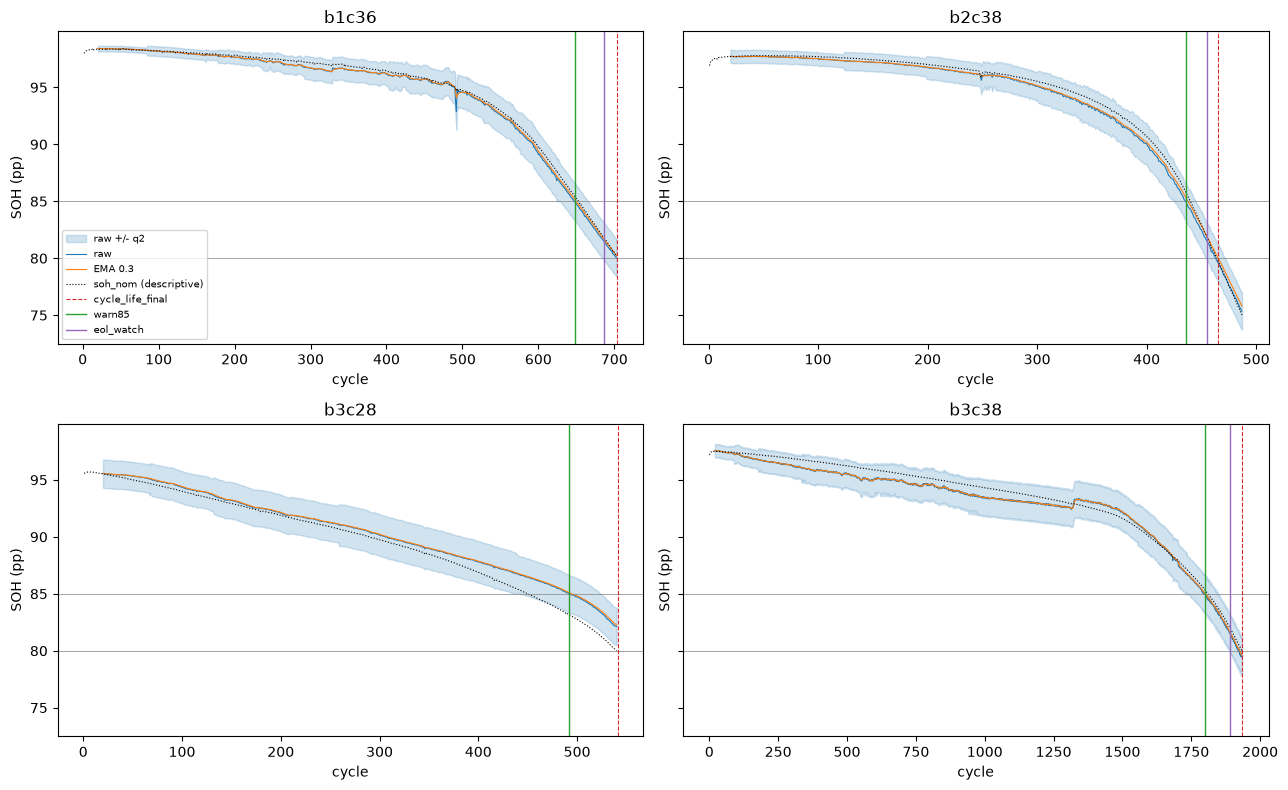

In [11]:
def feed_cell(mon, cid, cap=None, cache=True):
    b, i = parse_cell(cid)
    n = RAW.n_cycles(b, i)
    out = []
    for c in range(1, (n if cap is None else min(n, cap)) + 1):
        r = get_raw(cid, c, cache=cache)
        if r is None:
            continue
        rec = mon.ingest_cycle(cid, c, r[0], r[1], I=r[2], qd_total=r[4], t=r[3])
        out.extend(rec.pop("gap_records"))
        out.append(rec)
    return out


MON6 = hm.HealthMonitor(MODEL_DIR, CFG_PATHS, "W240", "M0", grid_path=P7A / "models" / "M0_W240.npz",
                        recipe=RECIPE, bin_convention=CONV)
REPLAY_DF, rows6, REJ = {}, [], []


def cls(a, b):
    if a is None and b is None:
        return "equal"
    if a is None or b is None:
        return "different"
    return "equal" if a == b else ("within 2" if abs(a - b) <= 2 else "different")


for cid in REPLAY:
    df = pd.DataFrame(feed_cell(MON6, cid, CAP))
    if "note" in df.columns:
        for _n in df.note.dropna():
            if str(_n).startswith("reference candidate rejected"):
                REJ.append((cid, re.sub(r"-?\d+\.?\d*", "#", str(_n))))
    labc = lab[lab.cell_id == cid]
    df["soh_nom"] = df.cycle.map(dict(zip(labc.cycle_number.astype(int), labc.soh_nom)))
    REPLAY_DF[cid] = df
    st = MON6.cells[cid]
    oc = OFFROWS[OFFROWS.cell_id == cid].sort_values("cycle")
    if CAP is not None:
        oc = oc[oc.cycle <= CAP]
    wf_off, _, ef_off = offline_fires(oc.cycle.values, oc.raw.values, oc.lb.values, oc.soh.values)
    ok = df[df.status == "OK"]
    mg = ok.merge(oc[["cycle", "raw", "soh"]].rename(columns={"raw": "raw_off"}), on="cycle")
    dd = np.abs(mg.raw - mg.raw_off)
    ref_lab = sorted(labc.loc[labc.is_ref.fillna(False).astype(bool), "cycle_number"].astype(int).tolist())
    q0_lab = float(labc.loc[labc.is_ref.fillna(False).astype(bool), "q0"].dropna().iloc[0])
    scored_cycles = set(oc.cycle.astype(int))
    rows6.append({
        "cell_id": cid, "batch": parse_cell(cid)[0], "life": LIFE[cid], "kind": "extra" if cid in EXTRA else "regular",
        "ref_monitor": st.ref_cycles, "ref_stored": ref_lab, "ref_equal": st.ref_cycles == ref_lab,
        "q0_monitor": st.q0, "q0_stored": q0_lab, "q0_diff": abs(st.q0 - q0_lab) if st.q0 is not None else np.nan,
        "n_ok": len(ok), "n_matched": len(mg), "raw_diff_max": dd.max(), "raw_diff_p99": dd.quantile(0.99), "raw_diff_median": dd.median(),
        "warn85_online": st.warn85_cycle, "warn85_offline": wf_off, "warn85_class": cls(st.warn85_cycle, wf_off),
        "warn85_online_first_unscored": st.warn85_cycle is not None and st.warn85_cycle not in scored_cycles,
        "eol_online": st.eol_cycle, "eol_offline": ef_off, "eol_class": cls(st.eol_cycle, ef_off),
        "eol_online_first_unscored": st.eol_cycle is not None and st.eol_cycle not in scored_cycles,
        "mae_vs_soh_nom_pp": float(np.abs(mg.raw - mg.soh).mean()), "median_minutes_into_discharge": float(ok.minutes_into_discharge.median()),
        "n_invalid": int((df.status == "INVALID_WINDOW").sum()), "n_stale": int((df.status == "STALE").sum())})
    cols = ["cell_id", "cycle", "status", "raw", "ema", "lo", "hi", "lower_bound", "warn85", "eol_watch", "stale", "latency_ms", "soh_nom", "minutes_into_discharge"]
    df[cols].to_parquet(OUT / "replay" / ("%s.parquet" % cid), index=False)
R6 = pd.DataFrame(rows6)
R6.to_csv(OUT / "s6_replay_per_cell.csv", index=False)
if REJ:
    emit("S6 rejected reference candidates (numbers masked as #)",
         pd.DataFrame(REJ, columns=["cell_id", "reason"]).value_counts().rename("count").reset_index().head(30))
say("replay MAE is descriptive only: batch-3 labels are spent and nothing was selected with them")
emit("S6 replay: references and Q0 (monitor vs labels table)", R6[["cell_id", "kind", "ref_monitor", "ref_stored", "ref_equal", "q0_monitor", "q0_stored", "q0_diff"]])
emit("S6 replay: online raw vs offline raw per cycle (pp) and descriptive MAE vs soh_nom (batch-3 labels spent)",
     R6[["cell_id", "n_ok", "n_matched", "raw_diff_max", "raw_diff_p99", "raw_diff_median", "mae_vs_soh_nom_pp", "median_minutes_into_discharge", "n_invalid", "n_stale"]])
emit("S6 replay: fire cycles online vs offline (offline over scored2 cycles only)",
     R6[["cell_id", "life", "warn85_online", "warn85_offline", "warn85_class", "warn85_online_first_unscored", "eol_online", "eol_offline", "eol_class", "eol_online_first_unscored"]])
pairs = pd.concat([R6.warn85_class, R6.eol_class])
S6_RES = {"share_equal": float((pairs == "equal").mean()), "n_pairs": int(len(pairs)), "n_different": int((pairs == "different").sum()),
          "n_within2": int((pairs == "within 2").sum())}
reg_rows = R6[R6.kind == "regular"]
S6_RES["refs_equal_regular"] = bool(reg_rows.ref_equal.all())
S6_RES["q0_diff_regular_max"] = float(reg_rows.q0_diff.max())
log("replay_written", {"cells": REPLAY, "parquet_dir": str(OUT / "replay"), "bin_convention": CONV, "smoke": SMOKE})

fig, axs = plt.subplots(2, 2, figsize=(13, 8), sharey=True)
FIG = [REPLAY[j] for j in (1, 5, 8, 11) if j < len(REPLAY)] or REPLAY[:4]
for ax, cid in zip(axs.ravel(), FIG):
    d = REPLAY_DF[cid]
    o = d[d.status.isin(["OK", "INVALID_WINDOW", "STALE"])]
    ax.fill_between(o.cycle, o.lo, o.hi, color="tab:blue", alpha=0.2, label="raw +/- q2")
    ax.plot(o.cycle, o.raw, color="tab:blue", lw=0.8, label="raw")
    ax.plot(o.cycle, o.ema, color="tab:orange", lw=0.8, label="EMA 0.3")
    ax.plot(d.cycle, d.soh_nom, color="k", lw=0.8, ls=":", label="soh_nom (descriptive)")
    ax.axhline(85, color="grey", lw=0.5)
    ax.axhline(80, color="grey", lw=0.5)
    ax.axvline(LIFE[cid], color="tab:red", lw=0.8, ls="--", label="cycle_life_final")
    st = MON6.cells[cid]
    if st.warn85_cycle:
        ax.axvline(st.warn85_cycle, color="tab:green", lw=1.0, label="warn85")
    if st.eol_cycle:
        ax.axvline(st.eol_cycle, color="tab:purple", lw=1.0, label="eol_watch")
    ax.set_title(cid)
    ax.set_xlabel("cycle")
    ax.set_ylabel("SOH (pp)")
axs[0, 0].legend(fontsize=7)
fig.tight_layout()
fig.savefig(OUT / "replay_four_cells.png", dpi=130)
plt.show()

## S8 unit tests

In [12]:
TCID = "b1c5"
GRID240 = P7A / "models" / "M0_W240.npz"


def mk(variant="M0"):
    return hm.HealthMonitor(MODEL_DIR, CFG_PATHS, "W240", variant, grid_path=GRID240, recipe=RECIPE, bin_convention=CONV)


def feed(mon, cid, items):
    out = []
    for c, r in items:
        rec = mon.ingest_cycle(cid, c, r[0], r[1], I=r[2], qd_total=r[4], t=r[3])
        out.extend(rec.pop("gap_records"))
        out.append(rec)
    return out


KEYS = ("cell_id", "cycle", "status", "raw", "ema", "lo", "hi", "lower_bound", "warn85", "eol_watch", "stale", "minutes_into_discharge")


def eq(a, b):
    for k in KEYS:
        x, y = a[k], b[k]
        if isinstance(x, float) and np.isnan(x):
            if not (isinstance(y, float) and np.isnan(y)):
                return False
        elif x != y:
            return False
    return True


def n_eq(A, B):
    return sum(eq(a, b) for a, b in zip(A, B)) if len(A) == len(B) else -1


STREAM = [(c, get_raw(TCID, c)) for c in range(1, 81)]
STREAM = [(c, r) for c, r in STREAM if r is not None]
_m = mk()
FULL = feed(_m, TCID, STREAM)
SS = _m.cells[TCID].score_start
REF_CLEAN = list(_m.cells[TCID].ref_cycles)
if SS is None:
    from collections import Counter
    _why = Counter(re.sub(r"-?\d+\.?\d*", "#", r["note"]) for r in FULL if r.get("note")).most_common(5)
    raise AssertionError("the monitor built no reference for the S8 test cell %s; rejection reasons: %s" % (TCID, _why))
BYC = {r["cycle"]: r for r in FULL}
G = SS + 5
assert STREAM[-1][0] > G + 5, "test stream too short for score_start %d" % SS
say("S8 test stream: cell %s, cycles %d..%d, reference cycles %s, score_start %d" % (TCID, STREAM[0][0], STREAM[-1][0], REF_CLEAN, SS))


def run_test(name, fn):
    try:
        ok, detail = fn()
    except Exception as e:
        ok, detail = False, "exception %r" % (e,)
    check("S8 " + name, "PASS" if ok else "FAIL", detail)


def t_a():
    k = SS + 10
    part = feed(mk(), TCID, [x for x in STREAM if x[0] <= k])
    ref = [r for r in FULL if r["cycle"] <= k]
    n = n_eq(part, ref)
    return n == len(ref), "%d of %d records for cycles <= %d identical to the full-stream run" % (n, len(ref), k)


def t_b():
    recs = feed(mk(), TCID, [x for x in STREAM if x[0] != G])
    st_ = [r for r in recs if r["cycle"] == G]
    nxt = [r for r in recs if r["cycle"] == G + 1]
    ok = (len(st_) == 1 and st_[0]["status"] == "STALE" and st_[0]["stale"] and st_[0]["raw"] == BYC[G - 1]["raw"]
          and len(nxt) == 1 and nxt[0]["status"] == "OK" and not nxt[0]["stale"] and nxt[0]["raw"] == BYC[G + 1]["raw"])
    return ok, "cycle %d missing: stale record raw %.5f == carried cycle %d raw %.5f; cycle %d fresh raw %.5f" % (
        G, st_[0]["raw"], G - 1, BYC[G - 1]["raw"], G + 1, nxt[0]["raw"])


def t_c():
    m = mk()
    items = []
    for x in STREAM:
        items.append(x)
        if x[0] == G:
            items.append(x)
    recs = feed(m, TCID, items)
    dup = [r for r in recs if r["status"] == "DUPLICATE"]
    rest = [r for r in recs if r["status"] != "DUPLICATE"]
    ok = len(dup) == 1 and dup[0]["cycle"] == G and dup[0]["raw"] == BYC[G]["raw"] and n_eq(rest, FULL) == len(FULL) and m.cells[TCID].n_ingested == len(STREAM)
    return ok, "%d duplicate record(s) ignored; other %d records identical to the clean run; cycles counted %d of %d" % (len(dup), n_eq(rest, FULL), m.cells[TCID].n_ingested, len(STREAM))


def t_d():
    items = []
    for x in STREAM:
        items.append(x)
        if x[0] == G + 3:
            items.append((G, dict(STREAM)[G]))
    recs = feed(mk(), TCID, items)
    ooo = [r for r in recs if r["status"] == "OUT_OF_ORDER"]
    rest = [r for r in recs if r["status"] != "OUT_OF_ORDER"]
    return len(ooo) == 1 and n_eq(rest, FULL) == len(FULL), "%d out-of-order record(s) ignored; other %d of %d records identical" % (len(ooo), n_eq(rest, FULL), len(FULL))


def t_e():
    m = mk()
    out = []
    for j, (c, r) in enumerate(STREAM[29:35]):
        out.append(m.ingest_cycle("late1", 100 + j, r[0], r[1], I=r[2], qd_total=r[4], t=r[3]))
    ok = all(o["status"] == "NO_REFERENCE" and np.isnan(o["raw"]) for o in out) and m.cells["late1"].qref is None
    return ok, "statuses %s; estimates all NaN: %s" % (sorted({o["status"] for o in out}), all(np.isnan(o["raw"]) for o in out))


def corrupt(kind, r):
    V, Q = r[0].copy(), r[1].copy()
    L = tau_len(V, r[2])
    s = int(np.flatnonzero(r[2] <= -1.0)[0])
    if kind == "NaN in V":
        V[s + (L - s) // 2] = np.nan
    elif kind == "non-monotone step":
        Q[L - 80:] -= 0.1
    else:
        Q[L - 80:L - 40] += 0.5
    return (V, Q, r[2], r[3], r[4])


def t_f():
    k = SS + 3
    parts = []
    ok_all = True
    for kind in ("NaN in V", "non-monotone step", "spike"):
        items = [x for x in STREAM if x[0] < k] + [(k, corrupt(kind, dict(STREAM)[k]))] + [x for x in STREAM if x[0] == k + 1]
        recs = feed(mk(), TCID, items)
        bad, nxt = [r for r in recs if r["cycle"] == k][0], [r for r in recs if r["cycle"] == k + 1][0]
        ok = bad["status"] == "INVALID_WINDOW" and bad["stale"] and bad["raw"] == BYC[k - 1]["raw"] and nxt["status"] == "OK" and nxt["raw"] == BYC[k + 1]["raw"]
        ok_all &= ok
        parts.append("%s -> %s (%s)" % (kind, bad["status"], bad.get("note", "")))
    return ok_all, "; ".join(parts) + "; carried raw equals previous estimate; next clean cycle scored normally"


def t_g():
    items = []
    for c, r in STREAM[:30]:
        V, qs = r[0], r[4]
        if c == 9:
            V = V.copy()
            V[100] = np.nan
        if c == 10:
            qs = qs + 0.05
        items.append((c, (V, r[1], r[2], r[3], qs)))
    m = mk()
    feed(m, TCID, items)
    st = m.cells[TCID]
    ok = 9 not in st.ref_cycles and 10 not in st.ref_cycles and len(st.ref_cycles) == 5 and st.ref_last > max(REF_CLEAN) and st.score_start == st.ref_last + 8
    return ok, "clean references %s; with cycles 9 (NaN) and 10 (capacity mismatch) corrupted: %s, ref_last %s, score_start %s" % (REF_CLEAN, st.ref_cycles, st.ref_last, st.score_start)


def t_g2():
    res = []
    for scale in (0.8, 1.10):
        items = [(c, (r[0], r[1], r[2] * scale if c == 9 else r[2], r[3], r[4])) for c, r in STREAM[:30]]
        m = mk()
        feed(m, TCID, items)
        st = m.cells[TCID]
        res.append((scale, 9 not in st.ref_cycles and len(st.ref_cycles) == 5))
    return all(ok for _, ok in res), "cycle 9 with discharge current scaled x0.8 / x1.10 rejected as a reference (and 5 references still built): %s" % res


def t_h():
    t0 = SS + 5
    mA = mk()
    feed(mA, TCID, [x for x in STREAM if x[0] <= t0])
    d = json.loads(json.dumps(mA.state_dict(TCID)))
    mB = mk()
    mB.load_state(d)
    rest = [x for x in STREAM if x[0] > t0]
    A, B = feed(mA, TCID, rest), feed(mB, TCID, rest)
    same_state = json.dumps(mA.state_dict(TCID), sort_keys=True) == json.dumps(mB.state_dict(TCID), sort_keys=True)
    return n_eq(A, B) == len(A) and same_state, "%d of %d future records identical after JSON round-trip at cycle %d; final states identical: %s" % (n_eq(A, B), len(A), t0, same_state)


def t_i():
    cells = [c for c in kept.cell_id if c in QREF][:24]
    items, refl = [], {}
    for cid in cells:
        g = sc[sc.cell_id == cid]
        p = g.index[int(np.argmin(np.abs(g.cycle_number.values - 300)))]
        items.append({"cell_id": cid, "cycle": int(cyc_a[p]), "window": np.asarray(QD[sc.row_id[p], :734], dtype=np.float64), "q0": Q0S[cid]})
        refl[cid] = int(sc.ref_last[p])
    mF, mP = mk(), mk()
    for cid in cells:
        mF.set_reference(cid, QREF[cid], Q0S[cid], refl[cid])
        mP.set_reference(cid, QREF[cid], Q0S[cid], refl[cid])
    F = mF.update_fleet(items)
    P = [mP.update_window(it["cell_id"], it["cycle"], it["window"], it["q0"]) for it in items]
    okc = [i for i in range(len(items)) if F[i]["status"] == "OK" and P[i]["status"] == "OK"]
    diff = max(abs(F[i]["raw"] - P[i]["raw"]) for i in okc) if okc else np.inf
    tol = max(1e-6, float(np.spacing(np.float32(100.0))))
    return (len(okc) >= 20 and diff <= tol and all(F[i]["status"] == P[i]["status"] for i in range(len(items)))), \
        "%d cells, %d scored in both; max |fleet - per-cell| = %.3e pp (limit %.2e = max(1e-6, one float32 ulp at 100 pp))" % (len(items), len(okc), diff, tol)


def t_j():
    tree = ast.parse(MOD_PATH.read_text(encoding="utf-8"))
    names = []
    for n in ast.walk(tree):
        if isinstance(n, ast.Import):
            names += [a.name for a in n.names]
        elif isinstance(n, ast.ImportFrom):
            names.append(n.module or "")
    bad_static = [n for n in names if n.split(".")[0] == "torch" or "soh_deep" in n]
    code = ("import sys; sys.path.insert(0, r'%s'); import src.health_monitor; "
            "print(sorted(m for m in sys.modules if m.split('.')[0]=='torch' or 'soh_deep' in m))" % ROOT)
    pr = subprocess.run([sys.executable, "-c", code], capture_output=True, text=True)
    return (not bad_static and pr.returncode == 0 and pr.stdout.strip() == "[]"), \
        "static imports %s; fresh-interpreter import leaves torch/soh_deep modules: %s" % (sorted(set(names)), pr.stdout.strip() or pr.stderr.strip()[-200:])


def t_k():
    m = mk("M0idx")
    recs = feed(m, TCID, [x for x in STREAM if x[0] <= SS + 3])
    last = recs[-1]
    return m.experimental and last["status"] == "OK" and np.isfinite(last["raw"]), \
        "variant M0idx (experimental=%s) cycle %d raw %.4f pp vs M0 %.4f pp" % (m.experimental, last["cycle"], last["raw"], BYC[last["cycle"]]["raw"])


def t_l():
    m = mk()
    recs = []
    for c, r in [x for x in STREAM if x[0] <= SS + 3]:
        got = None
        for k in range(len(r[0])):
            rr = m.ingest_sample(TCID, c, float(r[0][k]), float(r[1][k]), float(r[2][k]), float(r[3][k]))
            if rr is not None and got is None:
                got = rr
        rr = m.end_cycle(TCID, r[4])
        recs.append(got if got is not None else rr)
    ref = [BYC[c] for c, _ in STREAM if c <= SS + 3]
    n_ok = sum(a["status"] == b["status"] and (a["raw"] == b["raw"] or (np.isnan(a["raw"]) and np.isnan(b["raw"]))) for a, b in zip(recs, ref))
    return n_ok == len(ref), "%d of %d per-sample-path records equal the cycle-path records (status and raw)" % (n_ok, len(ref))


for nm, fn in [("(a) causality", t_a), ("(b) missing cycle -> stale carry-forward", t_b), ("(c) duplicate ignored", t_c),
               ("(d) out-of-order ignored", t_d), ("(e) late joiner -> NO_REFERENCE", t_e), ("(f) corrupted windows -> INVALID_WINDOW", t_f),
               ("(g) bad reference candidates skipped", t_g),
               ("(g2) bad discharge current rejected", t_g2), ("(h) to_dict/from_dict round-trip", t_h), ("(i) fleet == per-cell", t_i),
               ("(j) no torch import", t_j), ("(k) M0idx variant runs (experimental)", t_k), ("(l) per-sample path == cycle path", t_l)]:
    run_test(nm, fn)

S8 test stream: cell b1c5, cycles 2..80, reference cycles [8, 9, 10, 11, 12], score_start 20
[PASS] S8 (a) causality: 29 of 29 records for cycles <= 30 identical to the full-stream run
[PASS] S8 (b) missing cycle -> stale carry-forward: cycle 25 missing: stale record raw 98.28078 == carried cycle 24 raw 98.28078; cycle 26 fresh raw 98.28963
[PASS] S8 (c) duplicate ignored: 1 duplicate record(s) ignored; other 79 records identical to the clean run; cycles counted 79 of 79
[PASS] S8 (d) out-of-order ignored: 1 out-of-order record(s) ignored; other 79 of 79 records identical
[PASS] S8 (e) late joiner -> NO_REFERENCE: statuses ['NO_REFERENCE']; estimates all NaN: True
[PASS] S8 (f) corrupted windows -> INVALID_WINDOW: NaN in V -> INVALID_WINDOW (1 non-finite samples before tau); non-monotone step -> INVALID_WINDOW (non-monotone (min step -0.0370 Ah)); spike -> INVALID_WINDOW (non-monotone (min step -0.0745 Ah)); carried raw equals previous estimate; next clean cycle scored normally
[PASS] 

## S9 full-pipeline latency (CPU, ONNX Runtime 1 thread)

In [13]:
say("REMINDER before timing: connect the charger, set the High-performance power plan and close other applications.")
say("Targets (my choice, from the proposal): per-cell update p99 <= 10 ms, fleet update median <= 50 ms; WARN, not FAIL, if missed.")
FL_CELLS = [c for c in kept.cell_id if c in QREF]
FL_ITEMS, FL_REF = [], {}
for cid in FL_CELLS:
    g = sc[sc.cell_id == cid]
    p = g.index[int(np.argmin(np.abs(g.cycle_number.values - 300)))]
    FL_ITEMS.append({"cell_id": cid, "cycle": 0, "window": np.asarray(QD[sc.row_id[p], :734], dtype=np.float64), "q0": Q0S[cid]})
    FL_REF[cid] = int(sc.ref_last[p])


def pq(x):
    x = np.asarray(x, dtype=float)
    return np.median(x), np.quantile(x, 0.95), np.quantile(x, 0.99)


def timed_pass():
    mon = mk()
    comp = {k: [] for k in ("ingest, per sample (us)", "window finalisation (ms)", "feature subsample (ms)", "ONNX call (ms)",
                            "post-processing (ms)", "total per cycle update (ms)")}
    for cid in REPLAY:
        b, i = parse_cell(cid)
        n = RAW.n_cycles(b, i)
        for c in range(1, (n if CAP is None else min(n, CAP)) + 1):
            r = get_raw(cid, c, cache=True)
            if r is None:
                continue
            rec = mon.ingest_cycle(cid, c, r[0], r[1], I=r[2], qd_total=r[4], t=r[3])
            if rec["status"] == "OK":
                lt = mon.last_timing
                comp["ingest, per sample (us)"].append(lt["ingest_s"] / max(lt["n_pushed"], 1) * 1e6)
                comp["window finalisation (ms)"].append(lt["window_s"] * 1e3)
                comp["feature subsample (ms)"].append(lt["subsample_s"] * 1e3)
                comp["ONNX call (ms)"].append(lt["onnx_s"] * 1e3)
                comp["post-processing (ms)"].append(lt["post_s"] * 1e3)
                comp["total per cycle update (ms)"].append(rec["latency_ms"])
    mf = mk()
    for cid in FL_CELLS:
        mf.set_reference(cid, QREF[cid], Q0S[cid], FL_REF[cid])
    fl = []
    for rep in range(REPEATS + 5):
        its = [dict(it, cycle=10000 + rep) for it in FL_ITEMS]
        t0 = time.perf_counter()
        mf.update_fleet(its)
        fl.append((time.perf_counter() - t0) * 1e3)
    return comp, fl[5:]


PASSES = [timed_pass() for _ in range(3)]
rows9 = []
for name in PASSES[0][0]:
    row = {"component": name}
    meds = []
    for j, (comp, _) in enumerate(PASSES, 1):
        m_, p95, p99 = pq(comp[name])
        row.update({"pass%d_median" % j: m_, "pass%d_p95" % j: p95, "pass%d_p99" % j: p99})
        meds.append(m_)
    row["median_spread_max/min"] = max(meds) / min(meds)
    rows9.append(row)
row = {"component": "fleet update, %d windows, one scorer call (ms)" % len(FL_ITEMS)}
meds = []
for j, (_, fl) in enumerate(PASSES, 1):
    m_, p95, p99 = pq(fl)
    row.update({"pass%d_median" % j: m_, "pass%d_p95" % j: p95, "pass%d_p99" % j: p99})
    meds.append(m_)
row["median_spread_max/min"] = max(meds) / min(meds)
rows9.append(row)
T9 = pd.DataFrame(rows9)
T9.to_csv(OUT / "s9_latency.csv", index=False)
emit("S9 latency, three passes side by side (ORT 1 thread; %d scored cycle updates per pass; fleet repeats %d)" % (len(PASSES[0][0]["total per cycle update (ms)"]), REPEATS), T9.round(4))
tot = T9[T9.component == "total per cycle update (ms)"].iloc[0]
flr = T9.iloc[-1]
cell_p99 = [float(tot["pass%d_p99" % j]) for j in (1, 2, 3)]
fleet_med = [float(flr["pass%d_median" % j]) for j in (1, 2, 3)]
check("S9 per-cell update p99 <= 10 ms", "PASS" if max(cell_p99) <= 10.0 else "WARN", "p99 per pass: %s ms" % [round(x, 3) for x in cell_p99])
check("S9 fleet update median <= 50 ms", "PASS" if max(fleet_med) <= 50.0 else "WARN", "median per pass: %s ms (%d cells, one scorer call)" % ([round(x, 3) for x in fleet_med], len(FL_ITEMS)))
check("S9 timing stability", "PASS" if T9.iloc[:, -1].max() <= 1.5 else "WARN",
      "largest spread of pass medians (max/min) = %.2fx over components; earlier measurements drifted up to 4.6x" % T9.iloc[:, -1].max())

REMINDER before timing: connect the charger, set the High-performance power plan and close other applications.
Targets (my choice, from the proposal): per-cell update p99 <= 10 ms, fleet update median <= 50 ms; WARN, not FAIL, if missed.

=== S9 latency, three passes side by side (ORT 1 thread; 10959 scored cycle updates per pass; fleet repeats 200) ===
                                      component  pass1_median  pass1_p95  pass1_p99  pass2_median  pass2_p95  pass2_p99  pass3_median  pass3_p95  pass3_p99  median_spread_max/min
                        ingest, per sample (us)        0.8356     1.7926     2.7582        0.8581     1.6213     2.3362        0.7725     1.4955     2.2767                 1.1108
                       window finalisation (ms)        0.1267     0.3939     0.6340        0.1361     0.3442     0.5670        0.1177     0.3180     0.5403                 1.1563
                         feature subsample (ms)        0.0058     0.0159     0.0343        0.0062     0.014

## S7 expectations: expected / observed / consistent

In [14]:
H20_ok = max(cell_p99) <= 10.0 and max(fleet_med) <= 50.0
obs = {
    "H16": ("p99 per-cycle max diff = %.5f Ah (share above 6e-3: %.4f)" % (S5_RES["win_p99"], S5_RES["win_share"]), S5_RES["win_p99"] <= 6e-3),
    "H17": ("median |diff| = %.5f pp, p99 = %.5f pp, max = %.5f pp" % (S5_RES["e2e_median"], S5_RES["e2e_p99"], S5_RES["e2e_max"]),
            S5_RES["e2e_median"] <= 0.02 and S5_RES["e2e_p99"] <= 0.10),
    "H18": ("references equal for all regular cells: %s; max Q0 diff = %.2e Ah" % (S6_RES["refs_equal_regular"], S6_RES["q0_diff_regular_max"]),
            S6_RES["refs_equal_regular"] and S6_RES["q0_diff_regular_max"] <= 1e-6),
    "H19": ("%.3f of %d pairs equal, %d within 2 cycles, %d different" % (S6_RES["share_equal"], S6_RES["n_pairs"], S6_RES["n_within2"], S6_RES["n_different"]),
            S6_RES["share_equal"] >= 0.90 and S6_RES["n_different"] == 0),
    "H20": ("per-cell p99 per pass %s ms; fleet median per pass %s ms" % ([round(x, 3) for x in cell_p99], [round(x, 3) for x in fleet_med]), H20_ok)}
EXP_TAB = pd.DataFrame([{"id": e["id"], "expected": e["statement"], "observed": obs[e["id"]][0], "consistent": "yes" if obs[e["id"]][1] else "NO"} for e in EXPECT])
emit("S7 expectations: expected / observed / consistent?", EXP_TAB)
for e in EXPECT:
    check("S7 " + e["id"], "PASS" if obs[e["id"]][1] else "WARN", obs[e["id"]][0])


=== S7 expectations: expected / observed / consistent? ===
 id                                                                                                  expected                                                                                       observed consistent
H16                                     online window vs stored Qdlin: p99 of per-cycle max |diff| <= 6e-3 Ah                                 p99 per-cycle max diff = 0.00434 Ah (share above 6e-3: 0.0049)        yes
H17                               online raw estimate vs offline: median |diff| <= 0.02 pp and p99 <= 0.10 pp                                 median |diff| = 0.03205 pp, p99 = 0.17344 pp, max = 6.56492 pp         NO
H18 monitor references and Q0 equal the stored ones for the 12 regular replay cells (b1c18, b1c41 may differ)                        references equal for all regular cells: True; max Q0 diff = 3.60e-08 Ah        yes
H19           replay fire cycles equal offline for >= 90% of cell x alert pa

## S10 report and artifacts

In [15]:
final_ok = hash_guard("end")
RUNTIME_MIN = (time.time() - T_START) / 60.0
check("runtime", "PASS" if (SMOKE or RUNTIME_MIN <= 25) else "WARN", "%.1f minutes (target under 25)" % RUNTIME_MIN)
summ = pd.Series([c["status"] for c in CHECKS]).value_counts().reindex(["PASS", "WARN", "FAIL"]).fillna(0).astype(int)
emit("check summary", summ.rename_axis("status").reset_index(name="count"))
emit("all checks", pd.DataFrame(CHECKS))
art = [{"artifact": str(p.relative_to(ROOT)), "bytes": p.stat().st_size} for p in sorted(OUT.rglob("*")) if p.is_file() and p.name != "phase8b_report.txt"]
art.append({"artifact": "src\\health_monitor.py", "bytes": MOD_PATH.stat().st_size})
emit("artifacts", pd.DataFrame(art))
say("sha256 of src\\health_monitor.py:", sha256_file(MOD_PATH))
say("smoke run: results are not to be quoted" if SMOKE else "full run")
(OUT / "phase8b_report.txt").write_text("\n".join(REPORT), encoding="utf-8")
json.dump({"smoke": SMOKE, "runtime_min": RUNTIME_MIN, "recipe": RECIPE, "bin_convention": CONV, "health_monitor_sha256": sha256_file(MOD_PATH),
           "frozen_hashes_unchanged": final_ok, "counts": {k: int(v) for k, v in summ.items()}, "checks": CHECKS,
           "expectations": EXP_TAB.to_dict("records"),
           "frozen_sha256": {k: sha256_file(v[0]) for k, v in EXPECTED.items()}},
          open(OUT / "verification_report.json", "w"), indent=1, default=str)
log("done", {"counts": {k: int(v) for k, v in summ.items()}, "runtime_min": RUNTIME_MIN, "bin_convention": CONV,
             "health_monitor_sha256": sha256_file(MOD_PATH), "report_sha256": sha256_file(OUT / "phase8b_report.txt")})
assert summ["FAIL"] == 0 and final_ok, "acceptance not met: %d FAIL" % summ["FAIL"]


=== hash guard (end) ===
                        file                                                           sha256  matches_expected
                M0_W240.onnx 4fe196d3f7787a4f2dcd5f20939447518afb032eb8dc724c018f891630945771              True
                M0_W300.onnx 4e8cd5235869301eb2694e4b56c346cdb816d06277db7a2914ed0af6580fd1d9              True
             M0idx_W240.onnx 50ea2ebbf287ab24a2385bdee8fbe0db4c725442cf4a3076a4daac8063ac2459              True
             M0idx_W300.onnx 4c94897e3f765671ad25a412c1f1b78810f660b6bf9262c43cd4d2e6ed2dcd79              True
              onnx_scorer.py 7f56bd5b5df08f7a37bc6104a140da2411b5290d25434a03aa8971599ec139c7              True
         monitor_config.json 638b6c3a6ad31c699fb77a22eb9fae72b571d6dc21ee65a73b41e849d7acb4b2              True
monitor_config_addendum.json d842e5f4c3186889ce8292e0654e1a0ca29d4434bcdeaf1bd3c7131479479632              True
  batch3_predictions.parquet 679ec76862de63f2615a710c7fc1f3ca2ec6c01149735bdd9